# Lab 01 — Simple Linear Regression (SLR)
## Dự đoán kết quả học tập của sinh viên: so sánh GPA clipping và no clipping

### Tóm tắt (Abstract)
Báo cáo nghiên cứu khả năng sử dụng hồi quy tuyến tính đơn để ước lượng GPA sau học kỳ (`Post_Semester_GPA`) từ từng đặc trưng riêng lẻ liên quan đến thói quen học tập, việc sử dụng Generative AI và GPA trước học kỳ. Năm mô hình hồi quy được xây dựng bằng Ordinary Least Squares (OLS). Với mỗi mô hình, hai chính sách dự đoán được so sánh: giữ nguyên đầu ra tuyến tính và giới hạn đầu ra vào thang GPA $[0,4]$. Thực nghiệm sử dụng các tập train, validation và test đã được cung cấp, cùng một giao thức đánh giá, Mean Baseline và 5-fold cross-validation. Các kết quả định lượng được sinh tự động khi chạy notebook; báo cáo cuối trình bày sai số, hệ số, khả năng giải thích và tác động của clipping. Nghiên cứu nhằm đánh giá liên hệ thống kê, không nhằm chứng minh quan hệ nhân quả giữa GenAI và thành tích học tập.

**Từ khóa:** Simple Linear Regression, Ordinary Least Squares, GPA prediction, clipping, residual analysis, model evaluation.

## 00 | Giới thiệu bài toán (Introduction)

### 00.1 | Bối cảnh và động lực
Việc sử dụng GenAI trong học tập đặt ra câu hỏi liệu các chỉ số sử dụng công cụ AI có chứa thông tin hữu ích cho việc ước lượng kết quả học tập hay không. Một mô hình hồi quy đơn biến là điểm khởi đầu dễ giải thích: mỗi mô hình chỉ xét một yếu tố, nhờ đó có thể quan sát chiều hướng liên hệ và mức sai số của từng yếu tố mà không cần một hệ thống phức tạp.

Bài toán thuộc **supervised learning – regression** vì dữ liệu có nhãn GPA dạng số liên tục (trên thang 0–4). Đầu vào là một giá trị đặc trưng $x$ của sinh viên; đầu ra là GPA dự đoán $\hat y$. Mục đích là xây dựng một baseline có thể đối chiếu với những mô hình hồi quy khác, bao gồm IRL.

### 00.2 | Câu hỏi nghiên cứu
1. Số giờ sử dụng GenAI mỗi tuần (M01) giải thích được bao nhiêu biến thiên của GPA sau học kỳ?
2. So với M01, các đặc trưng học tập còn lại có khả năng dự đoán tốt hơn hay không?
3. Việc giới hạn GPA dự đoán vào $[0,4]$ thay đổi sai số và tính hợp lệ của đầu ra như thế nào?
4. Mô hình có những sai số hệ thống nào, đặc biệt tại biên GPA = 4?

### 00.3 | Thiết kế đối chứng và phạm vi
- **Version A — No clipping:** fit OLS trên nhãn gốc và giữ dự đoán tuyến tính thô.
- **Version B — Clipping:** fit OLS tương tự A, nhưng chiếu dự đoán vào $[0,4]$ trong train evaluation, cross-validation, validation, test và inference.
- Hai phiên bản sử dụng cùng dữ liệu, đặc trưng, thuật toán fit và folds; điểm khác biệt duy nhất là quy tắc trả về prediction. **Clipping không nằm trong hàm loss tối ưu hệ số**; không cắt nhãn GPA và không huấn luyện bằng clipped loss.
- M01 là mô hình nghiên cứu chính; M02–M05 là đối chứng đơn biến. Mean Baseline dùng để tham chiếu hiệu năng, không tính là mô hình SLR thứ sáu.

### 00.4 | Cấu trúc báo cáo và cách chạy
Các mục 01–04 trình bày cấu hình, dữ liệu và EDA; mục 05–06 xây dựng và huấn luyện mô hình; mục 07–10 đánh giá, so sánh và phân tích sai số; mục 11–13 minh họa ứng dụng, thảo luận và tài liệu tham khảo.

Chạy bằng CPU trên Jupyter/VS Code/Colab/Kaggle. Cài `numpy`, `pandas`, `matplotlib`, `scikit-learn`, `ipython` và `python-dotenv`. Cấu hình `LAB01_DATA_ROOT` trong `.env` hoặc biến môi trường, trỏ tới thư mục chứa `train/dataset.csv`, `validation/dataset.csv`, `test/dataset.csv`. Chọn **Restart Kernel & Run All**. Không chia lại dữ liệu. Các số liệu thực nghiệm chỉ có giá trị với đúng ba file CSV và quy trình xử lý đã sử dụng.

## 01 | Môi trường thực nghiệm và lựa chọn biến (Experimental setup)

### 01.1 | Các đặc trưng và mục tiêu
Biến phụ thuộc $y$ là `Post_Semester_GPA`. Mỗi hàng tương ứng một quan sát sinh viên; `Student_ID` chỉ phục vụ kiểm tra dữ liệu, không được sử dụng để học mô hình.

| Mô hình | Biến độc lập $x$ | Lý do khảo sát |
|---|---|---|
| M01 | `Weekly_GenAI_Hours` | Đo liên hệ giữa thời lượng sử dụng GenAI hằng tuần và GPA. Đây là câu hỏi chính. |
| M02 | `Traditional_Study_Hours` | Đối chiếu với thời gian học theo phương thức truyền thống. |
| M03 | `Pre_Semester_GPA` | GPA trước kỳ cung cấp thông tin về kết quả học tập trước đó; là đối chứng dự báo tiềm năng. |
| M04 | `Tool_Diversity` | Khảo sát liên hệ với độ đa dạng công cụ. |
| M05 | `Perceived_AI_Dependency` | Khảo sát liên hệ với mức phụ thuộc AI được ghi nhận trên thang 1–10. |

Mỗi mô hình chỉ nhận một cột $X$ có kích thước $(n,1)$ và một vector nhãn $y$ kích thước $(n,)$. Không kết hợp năm biến thành một mô hình đa biến; do đó hệ số không phải ảnh hưởng riêng sau khi kiểm soát các yếu tố khác. Không cần chuẩn hóa feature để giải OLS đơn biến; giữ đơn vị gốc giúp giải thích slope trực tiếp.

### 01.2 | Khả năng tái lập
Cell sau nạp thư viện và tìm `.env` từ thư mục làm việc hiện tại lên các thư mục cha. Đường dẫn tương đối của `LAB01_DATA_ROOT` được giải theo `PROJECT_ROOT`. Các đường dẫn `TRAIN_CSV`, `VAL_CSV`, `TEST_CSV` là nguồn dữ liệu duy nhất. Seed 42 dùng cho việc tạo fold và lấy mẫu để vẽ, không dùng để chia lại CSV. Phiên bản thư viện được in nhằm hỗ trợ tái lập. Tỷ lệ train/validation/test được tính từ số mẫu thực tế sau cleaning, không mặc định là 70/15/15.

Mỗi lần Restart & Run All tạo thư mục `outputs/simple/runs/<RUN_ID>/` theo quy ước IRL. Biểu đồ được lưu PNG (170 dpi), bảng CSV, mô hình Joblib và metadata JSON. Cần thêm thư viện `joblib` (thường đã được cài cùng scikit-learn).

In [1]:
import os, sys, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display, Markdown
from dotenv import load_dotenv
SEED=42
cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (cwd, *cwd.parents) if (p / ".env").is_file()), cwd)
load_dotenv(PROJECT_ROOT / ".env")
print('PROJECT_ROOT:', PROJECT_ROOT)
configured_root = os.getenv("LAB01_DATA_ROOT")
if not configured_root:
    raise ValueError("Chưa cấu hình LAB01_DATA_ROOT trong .env hoặc biến môi trường")
DATA_ROOT = Path(configured_root).expanduser()
if not DATA_ROOT.is_absolute():
    DATA_ROOT = PROJECT_ROOT / DATA_ROOT
DATA_ROOT = DATA_ROOT.resolve()
TRAIN_CSV = DATA_ROOT / "train" / "dataset.csv"
VAL_CSV = DATA_ROOT / "validation" / "dataset.csv"
TEST_CSV = DATA_ROOT / "test" / "dataset.csv"
TARGET='Post_Semester_GPA'; ID='Student_ID'
FEATURES={'M01':'Weekly_GenAI_Hours','M02':'Traditional_Study_Hours','M03':'Pre_Semester_GPA','M04':'Tool_Diversity','M05':'Perceived_AI_Dependency'}
PRIMARY='M01'; BOUNDS=(0.,4.)
MODES={'No clipping':False,'Clipping':True}
print('Python:',sys.version.split()[0], 'sklearn:',sklearn.__version__, 'numpy:',np.__version__, 'pandas:',pd.__version__)
display(pd.Series(FEATURES,name='Single feature').rename_axis('Model').to_frame())

# Output layout — same run-based convention as IRL.
import json, uuid, joblib
from datetime import datetime, timezone
ROOT = DATA_ROOT.parent if DATA_ROOT.is_dir() else PROJECT_ROOT
RUN_ID = datetime.now().strftime('%Y%m%d_%H%M%S') + '_' + uuid.uuid4().hex[:7]
OUT_ROOT = ROOT / 'outputs' / 'simple'
OUT = OUT_ROOT / 'runs' / RUN_ID
OUT.mkdir(parents=True, exist_ok=False)
FIG, TABLES, MODELS = OUT / 'figures', OUT / 'tables', OUT / 'models'
for folder in (FIG, TABLES, MODELS):
    folder.mkdir()
FIGURES_CREATED = []

def write_json(path, obj):
    path.write_text(json.dumps(obj, indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8')

def show(fig, name):
    dest = FIG / f'{name}.png'
    if dest.exists():
        raise FileExistsError(f'Figure already saved: {dest}. Restart & Run All for a new run.')
    fig.tight_layout()
    fig.savefig(dest, dpi=170, bbox_inches='tight')
    display(fig)
    plt.close(fig)
    FIGURES_CREATED.append(str(dest.relative_to(OUT)))

print('RUN_ID:', RUN_ID, '| Output:', OUT)


PROJECT_ROOT: D:\1_Study\3.Year 3\Semester_1\Intro_ML\Lab01
Python: 3.13.9 sklearn: 1.9.1 numpy: 2.5.5 pandas: 2.3.3


,Single feature
Model,
M01,Weekly_GenAI_Hours
M02,Traditional_Study_Hours
M03,Pre_Semester_GPA
M04,Tool_Diversity
M05,Perceived_AI_Dependency


RUN_ID: 20261125_105509_d606e49 | Output: D:\1_Study\3.Year 3\Semester_1\Intro_ML\Lab01\outputs\simple\runs\20261125_105509_d606e49


## 02 | Mô tả và tiền xử lý dữ liệu (Data preparation)

Dữ liệu được cung cấp ở dạng ba CSV đã phân chia. Trước khi huấn luyện, cần xác nhận các cột bắt buộc tồn tại, giá trị số có thể sử dụng và mỗi sinh viên có định danh duy nhất trong tập tương ứng.

### 02.1 | Quy trình kiểm tra
| Bước | Thao tác | Mục đích |
|---|---|---|
| Schema | Loại khoảng trắng ở tên cột, kiểm tra cột thiếu/trùng | Tránh đọc sai biến |
| Duplicate | Xóa các dòng trùng hoàn toàn | Tránh tăng trọng số ngoài ý muốn |
| Numeric conversion | `pd.to_numeric(errors='coerce')`, kiểm tra finite | Phát hiện chuỗi không chuyển được, NaN và vô cực |
| Domain validation | GPA trong [0,4], thời gian và độ đa dạng không âm, dependency trong [1,10] | Đảm bảo điều kiện miền giá trị mà notebook giả định |
| ID validation | Không thiếu ID, kiểm tra ID duy nhất sau lọc | Hỗ trợ kiểm tra rò rỉ giữa các tập |

Mẫu không đạt bị loại theo quy tắc cố định; không điền nhãn GPA thiếu bằng trung bình và không cắt GPA gốc. GPA bằng 4 là dữ liệu hợp lệ, không phải outlier cần loại. Không dùng thống kê test để xác định ngưỡng lọc. Tuy vậy, nếu tỷ lệ loại mẫu lớn hoặc khác nhau giữa các tập, complete-case filtering có thể gây sai lệch phân phối; cần báo cáo và xem xét.

### 02.2 | Cách đọc báo cáo Data Quality Audit
`Raw samples` là số dòng gốc, `Retained samples` là số dòng cuối cùng; `Retention rate (%)` càng gần 100% thì càng ít mẫu bị loại. Các nhóm lỗi numeric, domain và missing ID có thể chồng lặp, không được cộng trực tiếp để suy ra tổng số dòng bị loại. Mã SHA-256 nhận diện nội dung từng CSV để đối chiếu với IRL. Bảng dtype xác nhận các feature/target đã được chuyển thành dữ liệu số.

Cell này chỉ kiểm tra tính hợp lệ theo quy tắc đã đặt, không chứng minh nguồn dữ liệu chính xác hoặc đại diện cho sinh viên thực tế. Muốn so sánh công bằng với IRL cần xác nhận cùng CSV và cùng danh sách ID được giữ lại.

In [2]:
cols = list(FEATURES.values()) + [TARGET]
required_cols = [ID] + cols

def load_and_clean_dataset(path, split_name):
    path = Path(path)

    # 1. Kiểm tra đường dẫn
    if not path.is_file():
        raise FileNotFoundError(
            f"Không tìm thấy {split_name} dataset: {path}"
        )

    # 2. Đọc dataset
    raw = pd.read_csv(path)
    raw.columns = raw.columns.str.strip()

    if not raw.columns.is_unique:
        raise ValueError(f"{split_name}: Duplicate column names")

    missing_cols = set(required_cols) - set(raw.columns)

    if missing_cols:
        raise ValueError(
            f"{split_name}: Missing columns {missing_cols}"
        )

    # 3. Loại bỏ dữ liệu trùng lặp
    work = raw.drop_duplicates().copy()

    # 4. Chuyển đổi kiểu dữ liệu
    num = work[cols].apply(pd.to_numeric, errors="coerce")

    # 5. Kiểm tra giá trị hữu hạn
    finite = np.isfinite(num).all(axis=1)

    # 6. Kiểm tra miền giá trị hợp lệ
    valid = (
        num[TARGET].between(0, 4)
        & num["Pre_Semester_GPA"].between(0, 4)
        & num["Weekly_GenAI_Hours"].ge(0)
        & num["Traditional_Study_Hours"].ge(0)
        & num["Tool_Diversity"].ge(0)
        & num["Perceived_AI_Dependency"].between(1, 10)
    )

    # 7. Giữ lại dữ liệu hợp lệ
    keep = finite & valid & work[ID].notna()

    clean = num.loc[keep].copy()
    clean.insert(0, ID, work.loc[keep, ID])
    clean = clean.reset_index(drop=True)

    # 8. Kiểm tra dữ liệu sau khi làm sạch
    assert clean[ID].is_unique, f"{split_name}: Duplicate Student IDs"
    assert len(clean) >= 30, f"{split_name}: Insufficient data"

    # 9. Báo cáo chất lượng dữ liệu
    audit = {
        "Split": split_name,
        "Raw samples": len(raw),
        "Duplicates removed": len(raw) - len(work),
        "Invalid numeric": int((~finite).sum()),
        "Invalid domain": int((~valid).sum()),
        "Missing ID": int(work[ID].isna().sum()),
        "Total removed": len(raw) - len(clean),
        "Retained samples": len(clean),
        "Retention rate (%)": 100 * len(clean) / len(raw)
    }

    print(f"\n{'=' * 60}")
    print(f"Dataset: {split_name}")
    print(f"Path: {path}")
    print(f"Raw shape: {raw.shape}")
    print(f"Clean shape: {clean.shape}")
    print(f"SHA256: {hashlib.sha256(path.read_bytes()).hexdigest()}")

    return clean, audit


# Load từng tập dữ liệu
train_df, train_audit = load_and_clean_dataset(
    TRAIN_CSV, "Train"
)

val_df, val_audit = load_and_clean_dataset(
    VAL_CSV, "Validation"
)

test_df, test_audit = load_and_clean_dataset(
    TEST_CSV, "Test"
)

# Tổng hợp báo cáo chất lượng
audit_df = pd.DataFrame([
    train_audit,
    val_audit,
    test_audit
]).set_index("Split")

display(audit_df.round(4))

# Kiểm tra kiểu dữ liệu
display(
    train_df.dtypes.rename("Dtype").to_frame()
)


Dataset: Train
Path: D:\1_Study\3.Year 3\Semester_1\Intro_ML\Lab01\data\train\dataset.csv
Raw shape: (35000, 16)
Clean shape: (35000, 7)
SHA256: 9f2174454c59a1283e308b5a6b74c2f165f1694304706a08a6db8e82d5be1fd9

Dataset: Validation
Path: D:\1_Study\3.Year 3\Semester_1\Intro_ML\Lab01\data\validation\dataset.csv
Raw shape: (7500, 16)
Clean shape: (7500, 7)
SHA256: b3106a38788934ce332f16387a70c40729eaccd690aaa7e20727d7c51fbb9fdf

Dataset: Test
Path: D:\1_Study\3.Year 3\Semester_1\Intro_ML\Lab01\data\test\dataset.csv
Raw shape: (7500, 16)
Clean shape: (7500, 7)
SHA256: 17ac893e4fd04acd61680fdfd4645cbc47038da543315b9eb4f11a64d4b6e30b


,Raw samples,Duplicates removed,Invalid numeric,Invalid domain,Missing ID,Total removed,Retained samples,Retention rate (%)
Split,,,,,,,,
Train,35000,0,0,0,0,0,35000,100.0
Validation,7500,0,0,0,0,0,7500,100.0
Test,7500,0,0,0,0,0,7500,100.0


,Dtype
Student_ID,int64
Weekly_GenAI_Hours,float64
Traditional_Study_Hours,float64
Pre_Semester_GPA,float64
Tool_Diversity,int64
Perceived_AI_Dependency,int64
Post_Semester_GPA,float64


## 03 | Giao thức chia dữ liệu và kiểm soát rò rỉ (Evaluation protocol)

Ba tập đã được chia sẵn nên notebook không gọi `train_test_split()`.

| Tập | Vai trò | Không sử dụng cho |
|---|---|---|
| Train | EDA, học hệ số, 5-fold CV | Báo cáo khả năng tổng quát hóa cuối cùng |
| Validation | So sánh ứng viên và khóa lựa chọn theo RMSE | Điều chỉnh lựa chọn sau khi đã xem test |
| Test | Đánh giá cuối trên mô hình đã khóa | Chọn feature hoặc chỉnh mô hình |
| Development (train + validation) | Final refit sau khi khóa lựa chọn | CV ban đầu hoặc chọn mô hình |

Cell tiếp theo kiểm tra giao của ba tập `Student_ID`: tất cả số đếm giao phải bằng 0. Nếu không, dừng thực nghiệm để xử lý rò rỉ. Kiểm tra này chỉ phát hiện trùng ID, không bảo đảm loại bỏ mọi rò rỉ liên quan đến thời gian, nhóm sinh viên hay nguồn sinh dữ liệu.

Bảng split cho biết số lượng và tỷ lệ **sau** làm sạch. Tổng các tỷ lệ phải xấp xỉ 100% (sai khác do làm tròn). `dev` được tạo để chuẩn bị final refit nhưng chưa sử dụng để fit cho tới mục 09. Danh sách `folds` được tạo một lần từ train, bảo đảm hai chính sách clipping sử dụng cùng các fold. Tập test chỉ được dùng kiểm tra chất lượng/ID ở giai đoạn này, không dùng để EDA hay lựa chọn mô hình.

In [3]:
# Use the existing CSV partitions; never split them again.
train = train_df.copy()
val = val_df.copy()
test = test_df.copy()
frames = {'train': train, 'validation': val, 'test': test}

ids = {k: set(v[ID]) for k, v in frames.items()}
overlap = {
    'train / validation': len(ids['train'] & ids['validation']),
    'train / test': len(ids['train'] & ids['test']),
    'validation / test': len(ids['validation'] & ids['test'])
}
display(pd.Series(overlap, name='Overlapping Student IDs').to_frame())
assert not any(overlap.values()), f'Data leakage detected: {overlap}'

# Development set for final refit only (after validation selection).
dev = pd.concat([train, val], ignore_index=True)
total_samples = sum(len(frame) for frame in frames.values())
assert len(dev) == len(train) + len(val)
assert dev[ID].is_unique
assert total_samples == int(audit_df['Retained samples'].sum())

# Both clipping modes use exactly the same train-only folds.
folds = list(KFold(5, shuffle=True, random_state=SEED).split(train))
split_table = pd.DataFrame({
    'n': {k: len(v) for k, v in frames.items()},
    'percent': {k: 100 * len(v) / total_samples for k, v in frames.items()}
})
display(split_table.round(4))
print(f'Total retained samples: {total_samples:,} | Final refit: {len(dev):,}')
print('[PASS] No overlapping Student IDs. Existing CSV splits preserved.')

# Save data provenance and train-only CV fold assignments (fold numbering as IRL).
paths = {'train': TRAIN_CSV, 'validation': VAL_CSV, 'test': TEST_CSV}
provenance = {'run_id': RUN_ID, 'type': 'pre_existing_frozen_csv',
              'sha256': {k: hashlib.sha256(p.read_bytes()).hexdigest() for k,p in paths.items()},
              'counts': {k: len(v) for k,v in frames.items()},
              'raw_counts': {k: int(audit_df.loc[k.title(), 'Raw samples']) for k in frames},
              'paths': {k: str(p) for k,p in paths.items()}}
write_json(OUT / 'split_provenance.json', provenance)
audit_df.to_csv(TABLES / 'data_quality_audit.csv')
split_table.to_csv(TABLES / 'split_summary.csv', index_label='split')
assignment = np.empty(len(train), dtype=int)
for fid, (_, vi) in enumerate(folds):
    assignment[vi] = fid
pd.DataFrame({ID: train[ID], 'fold': assignment}).to_csv(TABLES / 'train_cv_fold_assignments.csv', index=False)


,Overlapping Student IDs
train / validation,0
train / test,0
validation / test,0


,n,percent
train,35000,70.0
validation,7500,15.0
test,7500,15.0


Total retained samples: 50,000 | Final refit: 42,500
[PASS] No overlapping Student IDs. Existing CSV splits preserved.


## 04 | Phân tích khám phá dữ liệu (Exploratory Data Analysis)

### 04.1 | Thống kê mô tả và phân phối
EDA chỉ thực hiện trên train để hiểu miền giá trị, độ phân tán và dạng liên hệ trước khi fit.

- **Mean, median:** mô tả trung tâm của phân phối; median ít nhạy với giá trị cực đoan hơn mean. Trong bảng `describe()`, cột `50%` chính là median.
- **Std, variance:** mức phân tán; variance có đơn vị bình phương của biến, std có đơn vị gốc.
- **Min/max, Q1, Q3:** phạm vi và các tứ phân vị. $IQR=Q_3-Q_1$ mô tả độ rộng 50% dữ liệu ở giữa. Điểm ngoài $[Q_1-1.5IQR,Q_3+1.5IQR]$ được đếm trong `IQR flags`, không tự động bị xóa.

### 04.2 | Tương quan với GPA sau học kỳ
Pearson đo mức liên hệ tuyến tính:

$$r=\frac{\sum_i(x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum_i(x_i-\bar x)^2\sum_i(y_i-\bar y)^2}}.$$

Spearman tính tương quan Pearson trên thứ hạng của các giá trị (xử lý đồng hạng), phù hợp để khảo sát liên hệ đơn điệu không nhất thiết tuyến tính. Cả hai thường nằm trong $[-1,1]$ nếu xác định được: dấu biểu thị chiều liên hệ, độ lớn tuyệt đối biểu thị cường độ. Giá trị gần 0 không loại trừ mọi dạng quan hệ phi tuyến. Hai hệ số khác nhau đáng kể là tín hiệu để xem thêm scatter plot, không phải bằng chứng tự động của phi tuyến. Nếu biến hằng số, tương quan có thể không xác định.

### 04.3 | Ý nghĩa histogram
Mỗi histogram có trục ngang là khoảng giá trị feature hoặc target; trục dọc là số sinh viên trong mỗi khoảng. Quan sát độ lệch, vùng tập trung, giá trị rời rạc, khoảng trống và các điểm gần biên. Không so trực tiếp độ cao giữa các biến khác đơn vị như giờ học và GPA.

Riêng `Post_Semester_GPA`, số mẫu đúng 4 được in để kiểm tra hiện tượng tích tụ tại trần (ceiling effect). Nếu có nhiều mẫu ở 4, hồi quy tuyến tính có thể không mô tả tốt sự bão hòa ở vùng này. Histogram không tự chứng minh GPA đã bị censor trong quá trình tạo dữ liệu; cần biết cơ chế sinh nhãn để kết luận. Phân phối feature/target không cần phải chuẩn để fit OLS.

,count,mean,std,min,25%,50%,75%,max,variance,IQR,IQR flags
Weekly_GenAI_Hours,35000.0,8.4449,8.3165,0.000,2.390,5.780,11.730,40.000,69.1646,9.340,1829
Traditional_Study_Hours,35000.0,11.2021,5.1615,1.000,7.540,11.170,14.710,35.860,26.6415,7.170,111
Pre_Semester_GPA,35000.0,3.1464,0.4775,1.183,2.834,3.210,3.520,3.998,0.2280,0.686,226
Tool_Diversity,35000.0,2.7970,1.1859,1.000,2.000,3.000,4.000,5.000,1.4063,2.000,0
Perceived_AI_Dependency,35000.0,3.5106,1.8258,1.000,2.000,3.000,5.000,10.000,3.3334,3.000,138
Post_Semester_GPA,35000.0,3.3495,0.4949,1.000,3.023,3.421,3.749,4.000,0.2450,0.726,233


,pearson,spearman
Weekly_GenAI_Hours,-0.0212,0.0063
Traditional_Study_Hours,0.1399,0.1426
Pre_Semester_GPA,0.9265,0.9172
Tool_Diversity,0.0263,0.0305
Perceived_AI_Dependency,-0.0165,-0.0060


Train GPA = 4: 3369 | %: 9.625714285714286


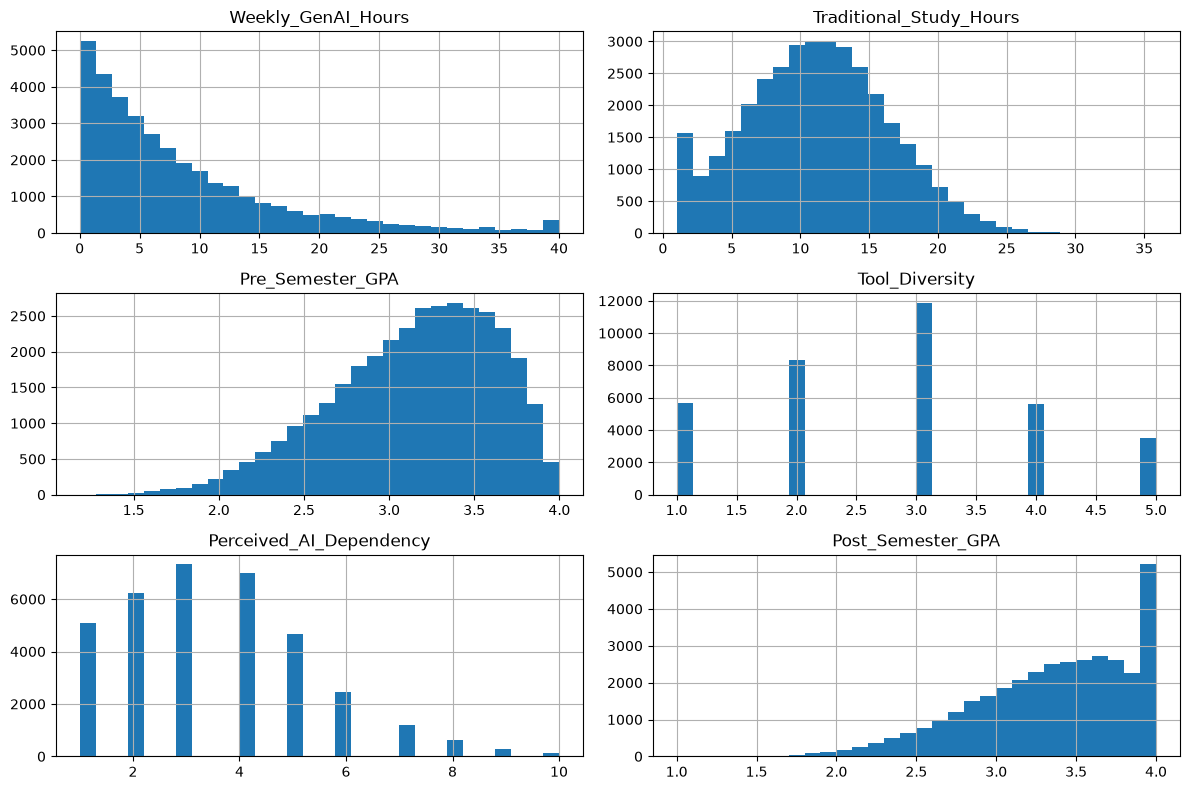

In [4]:
s=train[cols].describe().T; s['variance']=train[cols].var(); s['IQR']=s['75%']-s['25%']
s['IQR flags']=((train[cols]<s['25%']-1.5*s['IQR'])|(train[cols]>s['75%']+1.5*s['IQR'])).sum()
display(s.round(4))
correlations = pd.DataFrame({m:train[cols].corr(method=m)[TARGET].drop(TARGET) for m in ['pearson','spearman']})
display(correlations.round(4))
s.to_csv(TABLES / 'train_descriptive_statistics.csv', index_label='feature')
correlations.to_csv(TABLES / 'train_correlations.csv', index_label='feature')
print('Train GPA = 4:',int(train[TARGET].eq(4).sum()),'| %:',100*train[TARGET].eq(4).mean())
train[cols].hist(bins=30,figsize=(12,8)); show(plt.gcf(), '01_train_distributions')

### 04.4 | Mối quan hệ giữa từng feature và GPA (Scatter plot)

Mỗi subplot tương ứng một mô hình M01–M05. Trục $x$ là feature, trục $y$ là `Post_Semester_GPA`. Mỗi chấm là một sinh viên lấy mẫu từ train (tối đa 2.000 điểm để tránh chồng lấp); đường OLS được fit bằng **toàn bộ train**, không chỉ phần mẫu dùng vẽ. Đường ngang nét đứt ở GPA = 4 thể hiện giới hạn trên của thang điểm. Subplot thứ sáu bỏ trống vì chỉ có năm feature.

**Cách đọc:**
- Đường dốc lên/xuống cho thấy liên hệ tuyến tính dương/âm; đường gần ngang cho thấy thay đổi dự đoán nhỏ trong phạm vi $x$ quan sát.
- Chấm tập trung sát đường cho thấy sai số fit nhỏ; đám mây phân tán rộng theo chiều dọc cho thấy mô hình đơn biến khó giải thích GPA ở cùng một mức feature.
- Cụm điểm ngang tại 4 gợi ý sự bão hòa; đường hồi quy có thể đi qua biên này. Nếu xuất hiện đường cong hoặc hình phễu trong đám mây, cần kiểm tra thêm bằng residual plot.

Không so độ lớn slope trực tiếp giữa các feature khác đơn vị. Không suy ra nhân quả từ đường xu hướng; biểu đồ train cũng chưa phản ánh khả năng tổng quát hóa trên test. Những quan sát này là cơ sở để giải thích kết quả thực nghiệm ở các mục sau.

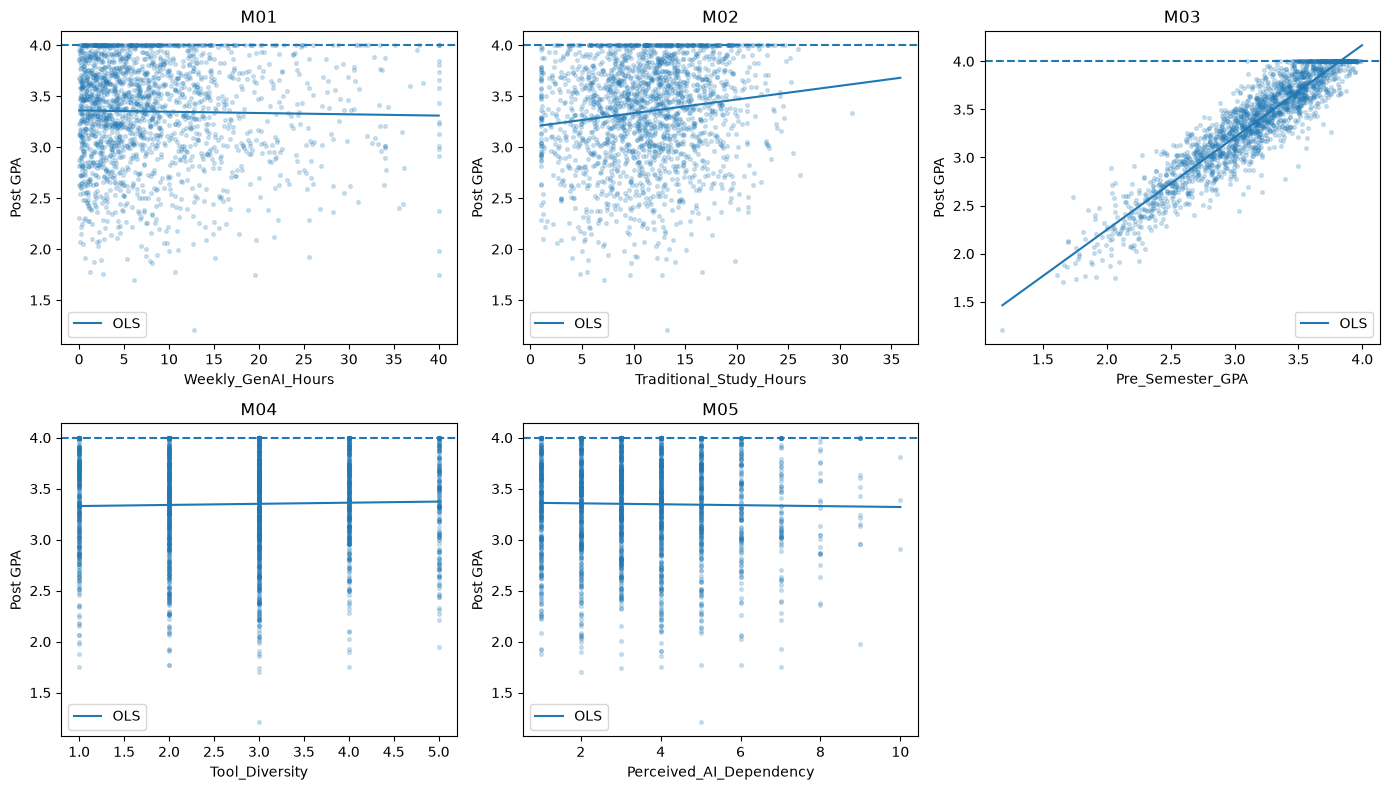

In [5]:
sample=train.sample(min(2000,len(train)),random_state=SEED)
fig,axes=plt.subplots(2,3,figsize=(14,8))
for ax,(mid,f) in zip(axes.flat,FEATURES.items()):
    grid=pd.DataFrame({f:np.linspace(train[f].min(),train[f].max(),200)})
    lr=LinearRegression().fit(train[[f]],train[TARGET])
    ax.scatter(sample[f],sample[TARGET],s=7,alpha=.2); ax.plot(grid[f],lr.predict(grid),label='OLS')
    ax.axhline(4,ls='--'); ax.set(title=mid,xlabel=f,ylabel='Post GPA'); ax.legend()
axes.flat[-1].axis('off'); show(fig, '02_train_feature_regression')

## 05 | Cơ sở lý thuyết và thiết kế mô hình (Methodology)

### 05.1 | Simple Linear Regression
Với $n$ quan sát $(x_i,y_i)$, SLR giả định phần trung bình có thể được xấp xỉ bằng một đường thẳng:

$$y_i=\beta_0+\beta_1 x_i+\varepsilon_i,\qquad z_i=\hat\beta_0+\hat\beta_1 x_i.$$

Trong đó $\beta_0$ là intercept, $\beta_1$ là slope và $\varepsilon_i$ là phần sai số chưa giải thích được. $z_i$ là prediction thô. Mỗi model có đúng một slope; đây là khác biệt với multiple linear regression, nơi có nhiều hệ số feature.

Slope dương/âm thể hiện GPA dự đoán thô tăng/giảm khi $x$ tăng một đơn vị. Intercept là GPA dự đoán khi $x=0$, có thể chỉ mang ý nghĩa toán học nếu 0 nằm ngoài miền feature quan sát.

### 05.2 | Ordinary Least Squares và hàm mất mát
Định nghĩa residual $e_i=y_i-z_i$. Ta muốn tìm đường thẳng có tổng bình phương residual nhỏ nhất. Bình phương tránh triệt tiêu sai số dương và âm, đồng thời phạt mạnh sai số lớn.

$$J(\beta_0,\beta_1)=\frac1n\sum_{i=1}^n(y_i-\beta_0-\beta_1x_i)^2.$$

Để tìm nghiệm tối ưu, lấy đạo hàm riêng và cho bằng 0:

$$\frac{\partial J}{\partial \beta_0}=-\frac2n\sum_i(y_i-\beta_0-\beta_1x_i)=0,$$

$$\frac{\partial J}{\partial \beta_1}=-\frac2n\sum_i x_i(y_i-\beta_0-\beta_1x_i)=0.$$

Từ phương trình đầu, $\beta_0=\bar y-\beta_1\bar x$. Thay vào phương trình thứ hai và rút gọn, thu được nghiệm đóng:

$$\hat\beta_1=\frac{\sum_i(x_i-\bar x)(y_i-\bar y)}{\sum_i(x_i-\bar x)^2},\qquad \hat\beta_0=\bar y-\hat\beta_1\bar x.$$

Tử số đo sự biến thiên đồng thời của $x$ và $y$; mẫu số đo mức phân tán của $x$. Khi $x$ có phương sai dương, bài toán bình phương tối thiểu là lồi và nghiệm slope/intercept là duy nhất. Nếu $x$ hằng số, công thức slope trên không xác định; không thể nhận diện slope duy nhất và cần xử lý riêng. OLS không cần chọn learning rate, số epoch hoặc chạy gradient descent. Với một feature, công thức NumPy minh họa trực tiếp cách thu được hệ số; `LinearRegression` của scikit-learn giải bài toán least squares bằng bộ giải số.

**Giả định và giới hạn:** quan hệ trung bình tuyến tính là giả định mô hình; tính độc lập, kỳ vọng sai số có điều kiện bằng 0 và các giả định về phương sai sai số quan trọng đối với suy luận thống kê cổ điển. Phân phối sai số chuẩn không phải điều kiện bắt buộc để tính nghiệm OLS. Notebook không thực hiện kiểm định giả thuyết hay khoảng tin cậy hệ số; đánh giá tập trung vào dự báo và sai số thực nghiệm.

### 05.3 | Hai chính sách GPA prediction
Version A giữ nguyên $\hat y_A=z$. Version B áp dụng phép chiếu:

$$\hat y_B=\operatorname{clip}(z,0,4)=\begin{cases}0&z<0\\z&0\le z\le4\\4&z>4.\end{cases}$$

Ví dụ minh họa (không phải kết quả dataset): $z=4.15$ trở thành $4.00$; $z=-0.2$ trở thành $0$; $z=3.2$ giữ nguyên. Hàm prediction B tuyến tính từng đoạn (piecewise linear), nhưng tham số bên trong vẫn được học bằng cùng OLS.

**Tại sao clipping không làm tăng sai số trên nhãn hợp lệ?** Với $y\in[0,4]$: nếu $z>4$, thì $|y-4|\le|y-z|$; nếu $z<0$, thì $|y-0|\le|y-z|$; trường hợp còn lại hai dự đoán bằng nhau. Bình phương và lấy trung bình bảo toàn bất đẳng thức. Vì vậy MAE/MSE/RMSE không tăng, và $R^2$ không giảm nếu tập nhãn có phương sai dương và được giữ cố định. Nếu không có prediction ngoài biên, toàn bộ metric giống nhau. Đây là lợi ích toán học của giới hạn miền đầu ra, không phải bằng chứng hệ số học tốt hơn.

**Phân biệt với clipping trong tối ưu:** notebook không tối thiểu hóa $\sum_i[y_i-\operatorname{clip}(\beta_0+\beta_1x_i,0,4)]^2$. Nó fit trên target gốc rồi mới clipping trong `predict()`, kể cả khi tính train metrics. Do đó A/B phải có cùng slope/intercept.

Cell sau kiểm tra công thức đóng cho M01 bằng NumPy và đối chiếu với hệ số scikit-learn bằng `assert_allclose`. Nếu thành công, phương trình in ra chính là đường OLS thô của M01 trên train.

In [6]:
f=FEATURES[PRIMARY]; x=train[f].to_numpy(); y=train[TARGET].to_numpy()
b1=((x-x.mean())*(y-y.mean())).sum()/((x-x.mean())**2).sum(); b0=y.mean()-b1*x.mean()
lr=LinearRegression().fit(train[[f]],y)
np.testing.assert_allclose([b0,b1],[lr.intercept_,lr.coef_[0]])
print(f'M01 manual OLS: GPA = {b0:.6f} + ({b1:.6f}) * {f}')

M01 manual OLS: GPA = 3.360195 + (-0.001261) * Weekly_GenAI_Hours


### 05.4 | Hiện thực mô hình và tiêu chí đánh giá (Implementation and metrics)

Class `GPARegressor` đóng gói `LinearRegression` theo giao diện estimator của scikit-learn:

| Hàm | Đầu vào | Đầu ra / vai trò |
|---|---|---|
| `fit(X, y)` | Ma trận một feature và GPA gốc | Học intercept, slope bằng OLS |
| `predict_raw(X)` | Feature mới | Giá trị $z$ chưa giới hạn |
| `predict(X)` | Feature mới | $z$ hoặc `np.clip(z, 0, 4)` tùy mode |
| `fit_models(frame)` | DataFrame train hoặc dev | 5 cặp estimator A/B |
| `compare(models, frame, split)` | Mô hình đã fit và tập đánh giá | Bảng metrics, số dự đoán ngoài miền |

Việc tách `predict_raw` và `predict` cho phép kiểm tra đầu ra ngoài miền trước khi projection ngay cả đối với phiên bản B. Hàm `metrics` luôn nhận dự đoán tương ứng với mode đang đánh giá.

### 05.5 | Công thức và cách diễn giải metric
Với tập đánh giá có $n$ mẫu, $e_i=y_i-\hat y_i$:

$$MAE=\frac1n\sum_i|e_i|,\qquad MSE=\frac1n\sum_i e_i^2,\qquad RMSE=\sqrt{MSE}.$$

$$R^2=1-\frac{\sum_i e_i^2}{\sum_i(y_i-\bar y)^2}.$$

| Metric | Ý nghĩa | Chiều tốt hơn |
|---|---|---|
| MAE | Khoảng cách tuyệt đối trung bình, đơn vị GPA | Thấp |
| MSE | Sai số bình phương trung bình, đơn vị GPA², nhạy với lỗi lớn | Thấp |
| RMSE | Căn MSE, đơn vị GPA; nhạy với lỗi lớn hơn MAE | Thấp |
| R² | Mức giảm SSE so với dự đoán bằng trung bình của chính tập đánh giá | Cao |
| Out of range (%) | Tỷ lệ dự đoán ngoài [0,4] sau chính sách prediction | Thấp |

$R^2=1$ biểu thị dự đoán hoàn hảo; 0 biểu thị SSE bằng mốc trung bình tập đánh giá; âm là SSE lớn hơn mốc đó. Đây không phải tỷ lệ dự đoán chính xác và có thể âm trên dữ liệu ngoài train. Nếu target hằng số, công thức thông thường không xác định (scikit-learn có quy ước xử lý riêng). Mean Baseline thực nghiệm dùng **trung bình của tập fit**, không phải trung bình test, nên R² của baseline trên test không nhất thiết bằng 0.

Ví dụ RMSE 0.2 có nghĩa độ lớn sai số bình phương trung bình theo thang GPA tương ứng 0.2 điểm sau lấy căn; không có nghĩa mọi prediction đều sai đúng 0.2. RMSE được chọn làm tiêu chí xếp hạng validation vì có cùng đơn vị GPA và nhạy với sai số lớn.

In [7]:
class GPARegressor(RegressorMixin,BaseEstimator):
    def __init__(self,clipping=False): self.clipping=clipping
    def fit(self,X,y):
        self.model_=LinearRegression().fit(X,y)
        return self
    def predict_raw(self,X): return self.model_.predict(X)
    def predict(self,X):
        z=self.predict_raw(X)
        return np.clip(z,*BOUNDS) if self.clipping else z

def metrics(y,p):
    mse=mean_squared_error(y,p)
    return {'MAE':mean_absolute_error(y,p),'MSE':mse,'RMSE':np.sqrt(mse),'R2':r2_score(y,p),'Below 0':int((p<0).sum()),'Above 4':int((p>4).sum()),'Out of range (%)':100*np.mean((p<0)|(p>4))}

def fit_models(frame):
    return {(mid,mode):GPARegressor(clip).fit(frame[[f]],frame[TARGET]) for mid,f in FEATURES.items() for mode,clip in MODES.items()}

def compare(models,frame,split):
    rows=[]
    for (mid,mode),model in models.items():
        f=FEATURES[mid]; p=model.predict(frame[[f]]); z=model.predict_raw(frame[[f]])
        rows.append({'Model':mid,'Feature':f,'Mode':mode,'Split':split,**metrics(frame[TARGET],p),'Raw above 4':int((z>4).sum()),'Raw below 0':int((z<0).sum())})
    return pd.DataFrame(rows)

## 06 | Huấn luyện và diễn giải hệ số (Training)

Với mỗi feature, huấn luyện hai estimator trên cùng tập train và cùng target. Không đưa validation/test vào `fit()`. Hai estimator có cùng nghiệm OLS; phép kiểm tra `assert_allclose` xác nhận intercept và slope của chúng giống nhau trong sai số số học.

### Cách đọc kết quả
- **Bảng coefficients:** slope là thay đổi dự đoán GPA thô khi feature tăng một đơn vị; với M01, đơn vị là GPA/giờ GenAI mỗi tuần. Với M03, slope phản ánh thay đổi GPA sau kỳ theo mỗi điểm GPA trước kỳ. Slope không phải tác động nhân quả và không được dùng để so tầm quan trọng giữa các feature khác đơn vị. Khi clipping đang hoạt động ở ngoài biên, thay đổi đầu ra có thể bằng 0 mặc dù slope của OLS khác 0.
- **Bảng train metrics:** mô tả độ phù hợp với dữ liệu đã dùng để học. So A/B trong cùng model để tách tác động clipping. `Raw above 4` và `Raw below 0` đếm prediction trước clipping; `Above 4`/`Below 0` đếm sau chính sách. Mode B phải không có đầu ra ngoài miền.
- **Mean Baseline:** luôn trả về GPA trung bình train. Nếu một SLR chỉ cải thiện rất ít so với baseline thì feature riêng lẻ đó có thể chứa ít thông tin tuyến tính hữu ích.

Training score tốt chưa đủ để kết luận mô hình tốt trên dữ liệu mới. Các mục tiếp theo đo hiệu năng ngoài tập fit.

In [8]:
models=fit_models(train); coef=[]
for mid,f in FEATURES.items():
    a,b=(models[(mid,mode)] for mode in MODES)
    np.testing.assert_allclose(a.model_.coef_,b.model_.coef_)
    np.testing.assert_allclose(a.model_.intercept_,b.model_.intercept_)
    coef.append({'Model':mid,'Feature':f,'Intercept':a.model_.intercept_,'Slope':a.model_.coef_[0]})
display(pd.DataFrame(coef).round(6))
train_results=compare(models,train,'train'); display(train_results.round(6))
print('Mean baseline train:',metrics(train[TARGET],np.full(len(train),train[TARGET].mean())))
pd.DataFrame(coef).to_csv(TABLES / 'coefficients.csv', index=False)
train_results.to_csv(TABLES / 'train_metrics.csv', index=False)


,Model,Feature,Intercept,Slope
0,M01,Weekly_GenAI_Hours,3.360195,-0.001261
1,M02,Traditional_Study_Hours,3.199253,0.013417
2,M03,Pre_Semester_GPA,0.328286,0.960220
3,M04,Tool_Diversity,3.318893,0.010960
4,M05,Perceived_AI_Dependency,3.365295,-0.004485


,Model,Feature,Mode,Split,MAE,MSE,RMSE,R2,Below 0,Above 4,Out of range (%),Raw above 4,Raw below 0
0,M01,Weekly_GenAI_Hours,No clipping,train,0.405155,0.244838,0.494811,0.000449,0,0,0.000000,0,0
1,M01,Weekly_GenAI_Hours,Clipping,train,0.405155,0.244838,0.494811,0.000449,0,0,0.000000,0,0
2,M02,Traditional_Study_Hours,No clipping,train,0.401011,0.240152,0.490053,0.019578,0,0,0.000000,0,0
3,M02,Traditional_Study_Hours,Clipping,train,0.401011,0.240152,0.490053,0.019578,0,0,0.000000,0,0
4,M03,Pre_Semester_GPA,No clipping,train,0.144732,0.034691,0.186256,0.858372,0,1508,4.308571,1508,0
5,M03,Pre_Semester_GPA,Clipping,train,0.142191,0.034310,0.185229,0.859930,0,0,0.000000,1508,0
6,M04,Tool_Diversity,No clipping,train,0.405066,0.244779,0.494751,0.000690,0,0,0.000000,0,0
7,M04,Tool_Diversity,Clipping,train,0.405066,0.244779,0.494751,0.000690,0,0,0.000000,0,0
8,M05,Perceived_AI_Dependency,No clipping,train,0.405151,0.244881,0.494854,0.000274,0,0,0.000000,0,0
9,M05,Perceived_AI_Dependency,Clipping,train,0.405151,0.244881,0.494854,0.000274,0,0,0.000000,0,0


Mean baseline train: {'MAE': 0.4051946195591836, 'MSE': 0.24494786923369066, 'RMSE': np.float64(0.49492208400281623), 'R2': 0.0, 'Below 0': 0, 'Above 4': 0, 'Out of range (%)': np.float64(0.0)}


## 07 | Kiểm định chéo 5-fold (Cross-validation)

### Thiết kế
Train được chia thành 5 fold bằng `KFold(shuffle=True, random_state=42)`. Tại lượt $k$, 4 fold được dùng để fit mô hình mới và fold còn lại để tính metrics. Mỗi quan sát train đóng vai trò đánh giá đúng một lượt; các fold được tái sử dụng y hệt cho mọi model và mode. Không dùng validation/test ở bước này.

Với metric $m_k$ của từng fold:

$$\bar m=\frac15\sum_{k=1}^5m_k,\qquad s_m=\sqrt{\frac{1}{4}\sum_{k=1}^5(m_k-\bar m)^2}.$$

Bảng mean/std của MAE, MSE, RMSE, R² và tỷ lệ ngoài miền mô tả hiệu năng và độ nhạy đối với việc thay đổi tập fit. Std là độ phân tán giữa các fold, không phải khoảng tin cậy hay kiểm định ý nghĩa thống kê. Mean RMSE qua fold khác với RMSE tính gộp trên toàn bộ out-of-fold prediction.

### Ý nghĩa biểu đồ 5-fold CV mean RMSE
Trục ngang là M01–M05, trục dọc là RMSE trung bình qua 5 fold, hai cột cạnh nhau đại diện cho A/B. Cột thấp hơn biểu thị sai số nhỏ hơn. Nếu cột hai mode trùng nhau, clipping có thể không tạo khác biệt hoặc khác biệt quá nhỏ để thấy trên thang vẽ. Biểu đồ chỉ thể hiện mean, **không có error bars**; muốn đánh giá ổn định cần đọc thêm cột std trong bảng. CV giúp kiểm tra độ ổn định nội bộ train chứ không thay thế test độc lập.

MAE                 MSE                RMSE            \
                       mean       std      mean       std      mean       std   
Model Mode                                                                      
M01   Clipping     0.405170  0.003876  0.244862  0.005096  0.494813  0.005177   
      No clipping  0.405170  0.003876  0.244862  0.005096  0.494813  0.005177   
M02   Clipping     0.401043  0.004213  0.240205  0.004600  0.490089  0.004710   
      No clipping  0.401043  0.004213  0.240205  0.004600  0.490089  0.004710   
M03   Clipping     0.142197  0.001967  0.034313  0.000956  0.185222  0.002591   
      No clipping  0.144737  0.001996  0.034694  0.000946  0.186250  0.002552   
M04   Clipping     0.405099  0.003956  0.244820  0.005134  0.494771  0.005217   
      No clipping  0.405099  0.003956  0.244820  0.005134  0.494771  0.005217   
M05   Clipping     0.405167  0.003884  0.244904  0.005089  0.494856  0.005169   
      No clipping  0.405167  0.003884  0.244904  0.005089  0.494856  0.005169   

                         R2           Out of range (%)            
                       mean       std             mean       std  
Model Mode                                                        
M01   Clipping     0.000242  0.000440         0.000000  0.000000  
      No clipping  0.000242  0.000440         0.000000  0.000000  
M02   Clipping     0.019218  0.005203         0.000000  0.000000  
      No clipping  0.019218  0.005203         0.000000  0.000000  
M03   Clipping     0.859904  0.002509         0.000000  0.000000  
      No clipping  0.858348  0.002366         4.297143  0.096044  
M04   Clipping     0.000415  0.000817         0.000000  0.000000  
      No clipping  0.000415  0.000817         0.000000  0.000000  
M05   Clipping     0.000071  0.000316         0.000000  0.000000  
      No clipping  0.000071  0.000316         0.000000  0.000000

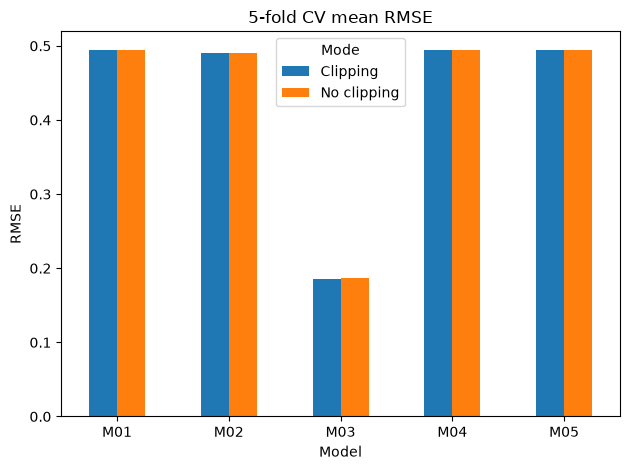

In [9]:
cv=pd.concat([compare(fit_models(train.iloc[tr]),train.iloc[va],f'fold {i}') for i,(tr,va) in enumerate(folds,1)],ignore_index=True)
display(cv.groupby(['Model','Mode'])[['MAE','MSE','RMSE','R2','Out of range (%)']].agg(['mean','std']).round(6))
cv.groupby(['Model','Mode']).RMSE.mean().unstack().plot.bar(rot=0,title='5-fold CV mean RMSE'); plt.ylabel('RMSE'); show(plt.gcf(), '03_cv_rmse')
cv.to_csv(TABLES / 'cv_folds.csv', index=False)
cv.groupby(['Model','Mode'])[['MAE','MSE','RMSE','R2','Out of range (%)']].agg(['mean','std']).to_csv(TABLES / 'cv_summary.csv')


## 08 | Validation và lựa chọn mô hình (Model selection)

Sau khi fit trên train, áp dụng từng model lên validation và tính cùng bộ metric. Tiêu chí đã xác định trước là RMSE thấp nhất trong từng mode; nếu RMSE bằng nhau, code sắp xếp thêm theo Model ID để lựa chọn có thể tái lập. Biến `selected` khóa hai ứng viên trước final refit. M01 luôn được báo cáo vì là câu hỏi nghiên cứu chính, dù ứng viên khác có RMSE thấp hơn.

### Ý nghĩa biểu đồ Validation RMSE
Trục $x$ thể hiện model, trục $y$ là RMSE trên validation. So hai cột của cùng model để đo tác động clipping, hoặc so các model trong cùng mode để chọn feature. Không chọn chỉ dựa trên màu hoặc chiều cao nhìn bằng mắt nếu hai cột gần nhau; dùng bảng số liệu chính xác. Đối chiếu Mean Baseline validation để xem hồi quy có cải thiện so với dự đoán trung bình train hay không.

Một model có thể tốt trên CV nhưng kém trên validation do khác biệt mẫu hoặc phân phối; ghi nhận sự khác biệt thay vì sửa split để đạt kết quả mong muốn. Không dùng test để thay đổi tiêu chí hoặc chọn lại ứng viên.

,Model,Feature,Mode,Split,MAE,MSE,RMSE,R2,Below 0,Above 4,Out of range (%),Raw above 4,Raw below 0
5,M03,Pre_Semester_GPA,Clipping,validation,0.141985,0.034508,0.185765,0.860537,0,0,0.000000,364,0
3,M02,Traditional_Study_Hours,Clipping,validation,0.402165,0.242298,0.492237,0.020779,0,0,0.000000,0,0
7,M04,Tool_Diversity,Clipping,validation,0.406537,0.247227,0.497219,0.000859,0,0,0.000000,0,0
1,M01,Weekly_GenAI_Hours,Clipping,validation,0.406659,0.247245,0.497238,0.000783,0,0,0.000000,0,0
9,M05,Perceived_AI_Dependency,Clipping,validation,0.406750,0.247405,0.497398,0.000140,0,0,0.000000,0,0
4,M03,Pre_Semester_GPA,No clipping,validation,0.144727,0.034922,0.186874,0.858867,0,364,4.853333,364,0
2,M02,Traditional_Study_Hours,No clipping,validation,0.402165,0.242298,0.492237,0.020779,0,0,0.000000,0,0
6,M04,Tool_Diversity,No clipping,validation,0.406537,0.247227,0.497219,0.000859,0,0,0.000000,0,0
0,M01,Weekly_GenAI_Hours,No clipping,validation,0.406659,0.247245,0.497238,0.000783,0,0,0.000000,0,0
8,M05,Perceived_AI_Dependency,No clipping,validation,0.406750,0.247405,0.497398,0.000140,0,0,0.000000,0,0


Locked selection: {'Clipping': 'M03', 'No clipping': 'M03'}
Mean baseline validation: {'MAE': 0.40674786607238095, 'MSE': 0.24743969489995513, 'RMSE': np.float64(0.49743310595491647), 'R2': -2.2823596759202758e-06, 'Below 0': 0, 'Above 4': 0, 'Out of range (%)': np.float64(0.0)}


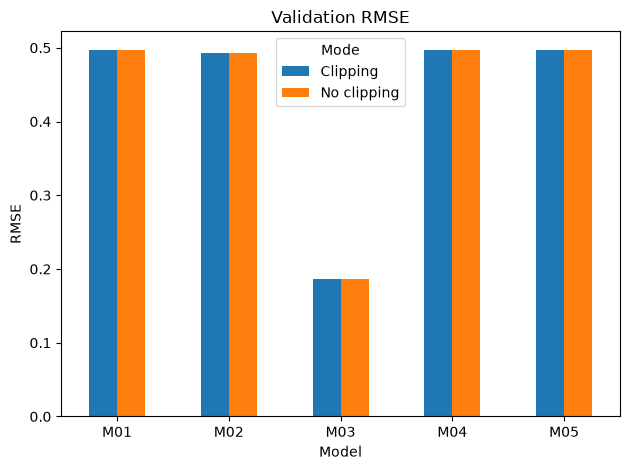

In [10]:
val_results=compare(models,val,'validation'); display(val_results.sort_values(['Mode','RMSE']).round(6))
selected=val_results.sort_values(['RMSE','Model']).groupby('Mode').first()['Model'].to_dict()
print('Locked selection:',selected)
print('Mean baseline validation:',metrics(val[TARGET],np.full(len(val),train[TARGET].mean())))
val_results.pivot(index='Model',columns='Mode',values='RMSE').plot.bar(rot=0,title='Validation RMSE'); plt.ylabel('RMSE'); show(plt.gcf(), '04_validation_rmse')
val_results.to_csv(TABLES / 'validation_metrics.csv', index=False)
# A tidy row per SLR configuration; development statistics only.
keys = ['Model','Feature','Mode']
metric_cols = ['MAE','MSE','RMSE','R2','Out of range (%)']
cv_agg = cv.groupby(keys)[metric_cols].agg(['mean','std'])
cv_agg.columns = [f'cv_{a}_{b}' for a,b in cv_agg.columns]
development = (train_results[keys + metric_cols].set_index(keys).add_prefix('train_')
               .join(cv_agg).join(val_results[keys + metric_cols].set_index(keys).add_prefix('val_')).reset_index())
development.to_csv(TABLES / 'development_comparison.csv', index=False)
model_lock = {'run_id': RUN_ID, 'selected_model': selected, 'selection_rule': 'validation RMSE per mode, ties by Model',
              'prediction_policies': ['raw_ols','clip_0_4'], 'test_used_to_select': False,
              'selection_date_utc': datetime.now(timezone.utc).isoformat(),
              'frozen_csv_sha256': provenance['sha256'], 'train_n': len(train),
              'validation_n': len(val), 'test_n': len(test)}
write_json(OUT / 'model_lock.json', model_lock)


## 09 | Final refit và đánh giá test (Results)

### 09.1 | Đánh giá cuối cùng
Khi lựa chọn validation đã khóa, fit lại cả năm cặp model trên `dev = train + validation` để tận dụng thêm nhãn trước khi dự đoán test. Mean Baseline cũng được tính lại từ GPA trung bình dev. Test không tham gia quá trình fit. Tất cả cấu hình được báo cáo để hoàn thiện so sánh đã định trước; không thay đổi lựa chọn theo kết quả test.

### 09.2 | So sánh định lượng clipping
Bảng `final_results` cho phép đọc metrics trên cùng test labels và số dự đoán ngoài miền. Bảng `delta` quy ước:

$$\Delta RMSE=RMSE_A-RMSE_B,\qquad \Delta R^2=R_B^2-R_A^2,$$

$$\text{RMSE improvement (\%)}=100\frac{RMSE_A-RMSE_B}{RMSE_A}.$$

Tương tự, delta MAE/MSE là giá trị A trừ B. Giá trị dương biểu thị B cải thiện theo quy ước này; 0 biểu thị không đổi. Tỷ lệ cải thiện cần RMSE A khác 0. Code xác nhận các delta không âm ngoài sai số làm tròn, phù hợp chứng minh ở mục 05 đối với GPA hợp lệ.

### 09.3 | Ý nghĩa hai biểu đồ test
| Biểu đồ | Trục và cách đọc |
|---|---|
| Final test RMSE | Trục ngang là model; trục dọc là RMSE (GPA). Cột thấp hơn cho thấy sai số dự báo thấp hơn. |
| Final test R² | Trục ngang là model; trục dọc là R². Cột cao hơn tốt hơn; cột âm cho thấy kém hơn mốc trung bình của chính test. |

Đọc hai biểu đồ kết hợp với MAE và tỷ lệ ngoài miền. RMSE và R² có cùng thứ tự xếp hạng trên một tập test cố định có phương sai dương vì đều phụ thuộc SSE. Chênh lệch clipping cần được đối chiếu với số raw predictions ngoài miền. Metric cải thiện nhờ projection không chứng minh học hệ số tốt hơn hoặc có ý nghĩa thống kê. Nếu model M01 có R² gần 0 và sai số gần baseline, kết luận phù hợp là feature giờ GenAI riêng lẻ có khả năng giải thích tuyến tính hạn chế trên tập này, không phải GenAI không ảnh hưởng GPA.

,Model,Feature,Mode,Split,MAE,MSE,RMSE,R2,Below 0,Above 4,Out of range (%),Raw above 4,Raw below 0
0,M01,Weekly_GenAI_Hours,No clipping,test,0.406447,0.247549,0.497543,-0.000687,0,0,0.000000,0,0
1,M01,Weekly_GenAI_Hours,Clipping,test,0.406447,0.247549,0.497543,-0.000687,0,0,0.000000,0,0
2,M02,Traditional_Study_Hours,No clipping,test,0.402022,0.243881,0.493843,0.014141,0,0,0.000000,0,0
3,M02,Traditional_Study_Hours,Clipping,test,0.402022,0.243881,0.493843,0.014141,0,0,0.000000,0,0
4,M03,Pre_Semester_GPA,No clipping,test,0.144377,0.034258,0.185088,0.861518,0,350,4.666667,350,0
5,M03,Pre_Semester_GPA,Clipping,test,0.141672,0.033837,0.183947,0.863219,0,0,0.000000,350,0
6,M04,Tool_Diversity,No clipping,test,0.406333,0.247340,0.497333,0.000157,0,0,0.000000,0,0
7,M04,Tool_Diversity,Clipping,test,0.406333,0.247340,0.497333,0.000157,0,0,0.000000,0,0
8,M05,Perceived_AI_Dependency,No clipping,test,0.406298,0.247403,0.497396,-0.000098,0,0,0.000000,0,0
9,M05,Perceived_AI_Dependency,Clipping,test,0.406298,0.247403,0.497396,-0.000098,0,0,0.000000,0,0


Mean baseline test: {'MAE': 0.4062804942180392, 'MSE': 0.2473795391475429, 'RMSE': np.float64(0.4973726361065141), 'R2': -2.4674534342405963e-06, 'Below 0': 0, 'Above 4': 0, 'Out of range (%)': np.float64(0.0)}


,MAE,MSE,RMSE,R2 gain,RMSE improvement (%)
Model,,,,,
M01,0.000000,0.000000,0.000000,0.000000,0.000000
M02,0.000000,0.000000,0.000000,0.000000,0.000000
M03,0.002704,0.000421,0.001141,0.001702,0.616225
M04,0.000000,0.000000,0.000000,0.000000,0.000000
M05,0.000000,0.000000,0.000000,0.000000,0.000000


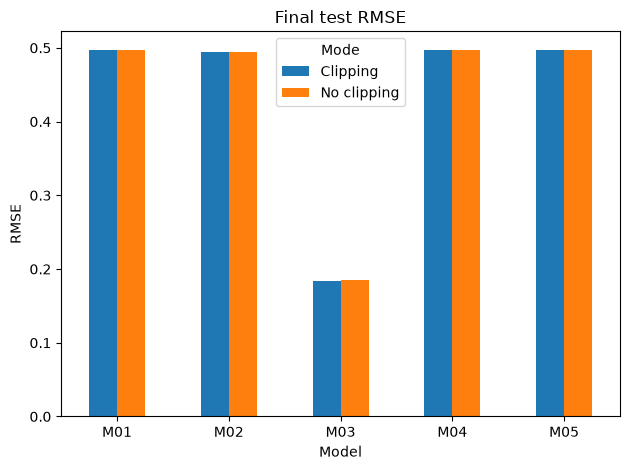

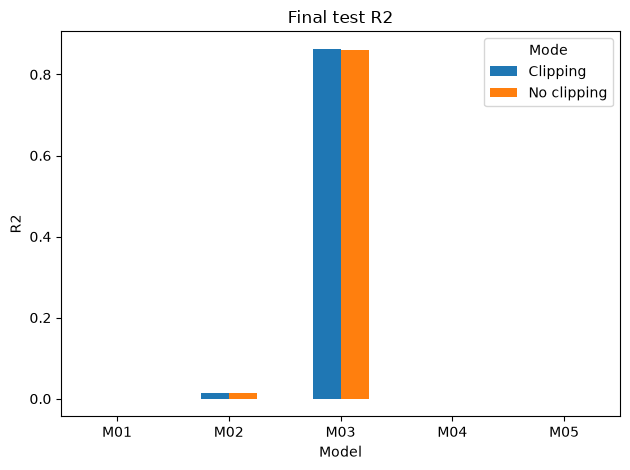

In [11]:
# Verify the frozen test file did not change after data loading.
if hashlib.sha256(TEST_CSV.read_bytes()).hexdigest() != provenance['sha256']['test']:
    raise RuntimeError('Test CSV changed after provenance audit.')
# Keep an audit trail of prior completed evaluations on the same test bytes.
prior_path = OUT_ROOT / f"final_test_dual_{provenance['sha256']['test']}.json"
previous_runs = []
if prior_path.exists():
    previous_runs.append(json.loads(prior_path.read_text(encoding='utf-8'))['run_id'])
    print('WARNING: test previously evaluated in run', previous_runs[0], '; not a new independent holdout.')
final_models=fit_models(dev); final_results=compare(final_models,test,'test'); display(final_results.round(6))
baseline_test=metrics(test[TARGET],np.full(len(test),dev[TARGET].mean())); print('Mean baseline test:',baseline_test)
pivot=final_results.pivot(index='Model',columns='Mode',values=['MAE','MSE','RMSE','R2'])
delta=pd.DataFrame({m:pivot[m]['No clipping']-pivot[m]['Clipping'] for m in ['MAE','MSE','RMSE']})
delta['R2 gain']=pivot['R2']['Clipping']-pivot['R2']['No clipping']; delta['RMSE improvement (%)']=100*delta.RMSE/pivot['RMSE']['No clipping']
display(delta.round(7)); assert (delta[['MAE','MSE','RMSE','R2 gain']]>=-1e-12).all().all()
for metric in ['RMSE','R2']:
    final_results.pivot(index='Model',columns='Mode',values=metric).plot.bar(rot=0,title=f'Final test {metric}'); plt.ylabel(metric); show(plt.gcf(), f'05_final_test_{metric.lower()}')

## 10 | Phân tích sai số và giới hạn của mô hình (Residual diagnostics)

Residual được định nghĩa $e_i=y_i-\hat y_i$. Residual dương nghĩa là dự đoán thấp hơn thực tế, residual âm nghĩa là dự đoán cao hơn thực tế. Hai model M01 (câu hỏi chính) và M03 (đối chứng GPA trước kỳ) được chọn trước để trực quan hóa. Scatter sử dụng tối đa 2.000 mẫu test với seed cố định; histogram residual sử dụng toàn bộ test, và các metrics cũng tính trên toàn test. Đường dự đoán được tạo từ các estimator đã fit trên dev.

### Cách đọc bốn biểu đồ cho mỗi model

**(a) Regression curve — trên trái.** Trục ngang là feature, trục dọc là GPA; các chấm là GPA thực tế test, hai đường là prediction của A/B theo miền feature quan sát trong dev. Đường ngang tại 4 đánh dấu trần GPA. Nếu đường A vượt 4 thì đường B nằm ngang ở 4; tương tự đối với biên 0 nếu xảy ra. Đường trùng nhau nghĩa là không có khác biệt trong miền vẽ hoặc khác biệt rất nhỏ. Độ phân tán quanh đường phản ánh phần biến thiên chưa được giải thích.

**(b) Actual vs predicted — trên phải.** Trục ngang là GPA thực tế, trục dọc là GPA dự đoán. Đường chéo $y=x$ là dự đoán hoàn hảo; điểm phía trên là overprediction, phía dưới là underprediction. Điểm càng gần đường chéo thì sai số càng nhỏ. Một dải prediction gần hằng số bất kể actual GPA có thể biểu thị model ít khả năng phân biệt sinh viên. Điểm nằm trên đường ngang prediction = 4 có thể do clipping.

**(c) Residual vs fitted — dưới trái.** Trục ngang là prediction, trục dọc là residual; đường ngang ở 0 biểu thị không sai số. Một đám mây phân tán tương đối ngẫu nhiên quanh 0 phù hợp hơn với giả định đường trung bình tuyến tính. Mẫu cong có thể gợi ý phi tuyến, hình phễu gợi ý phương sai sai số thay đổi; cụm ở biên có thể do thang GPA hữu hạn. Đây là chẩn đoán trực quan, không phải kiểm định chính thức.

**(d) Residual distribution — dưới phải.** Trục ngang là residual, trục dọc là số quan sát. Phân phối tập trung hẹp quanh 0 biểu thị nhiều sai số nhỏ; đuôi dài cho thấy có các lỗi lớn, và lệch khỏi 0 gợi ý xu hướng over/underprediction. Hai histogram có thể chồng nhau nếu clipping ít tác động; lưu ý các bin được tạo riêng cho từng mode, nên không đọc chênh lệch chiều cao từng bin như số mẫu thay đổi chính xác.

**Giới hạn diễn giải:** residual không cần có phân phối chuẩn để fit OLS hoặc tính RMSE. Các pattern chỉ giúp phát hiện điểm yếu và đề xuất nghiên cứu tiếp theo; không dùng chúng để điều chỉnh mô hình rồi báo lại kết quả trên cùng test.

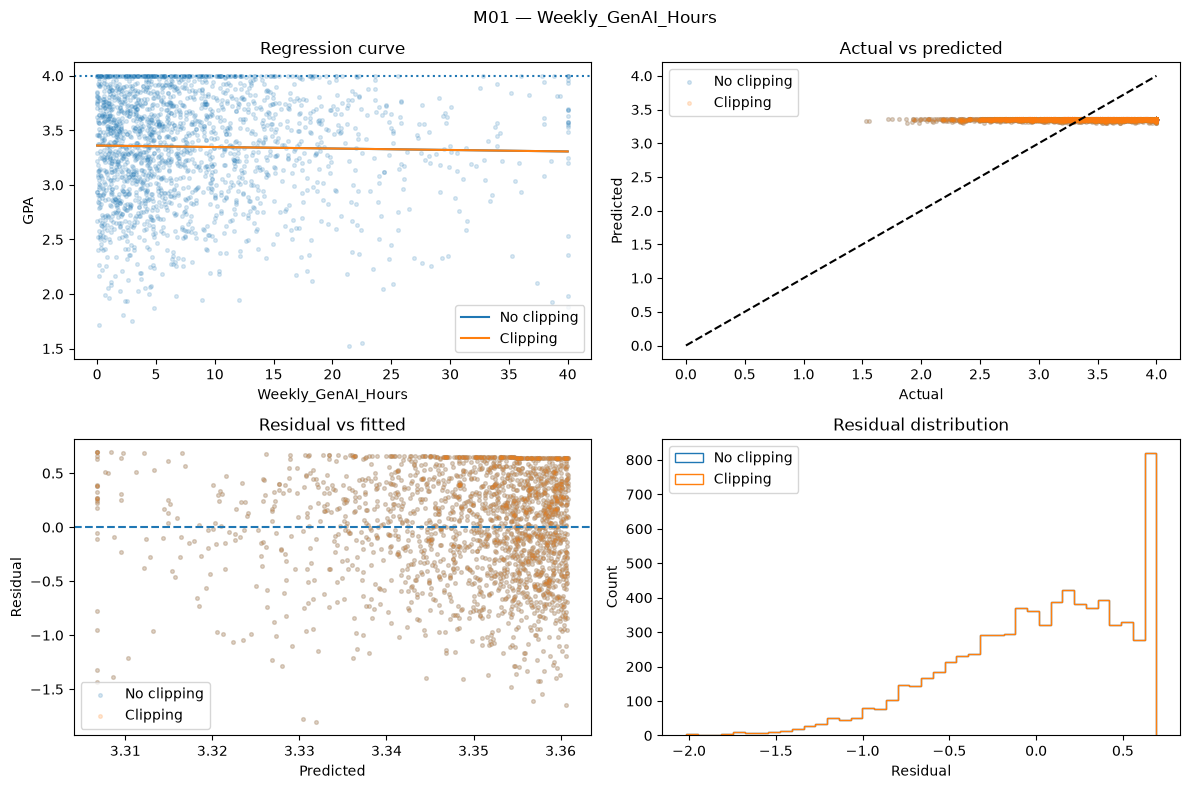

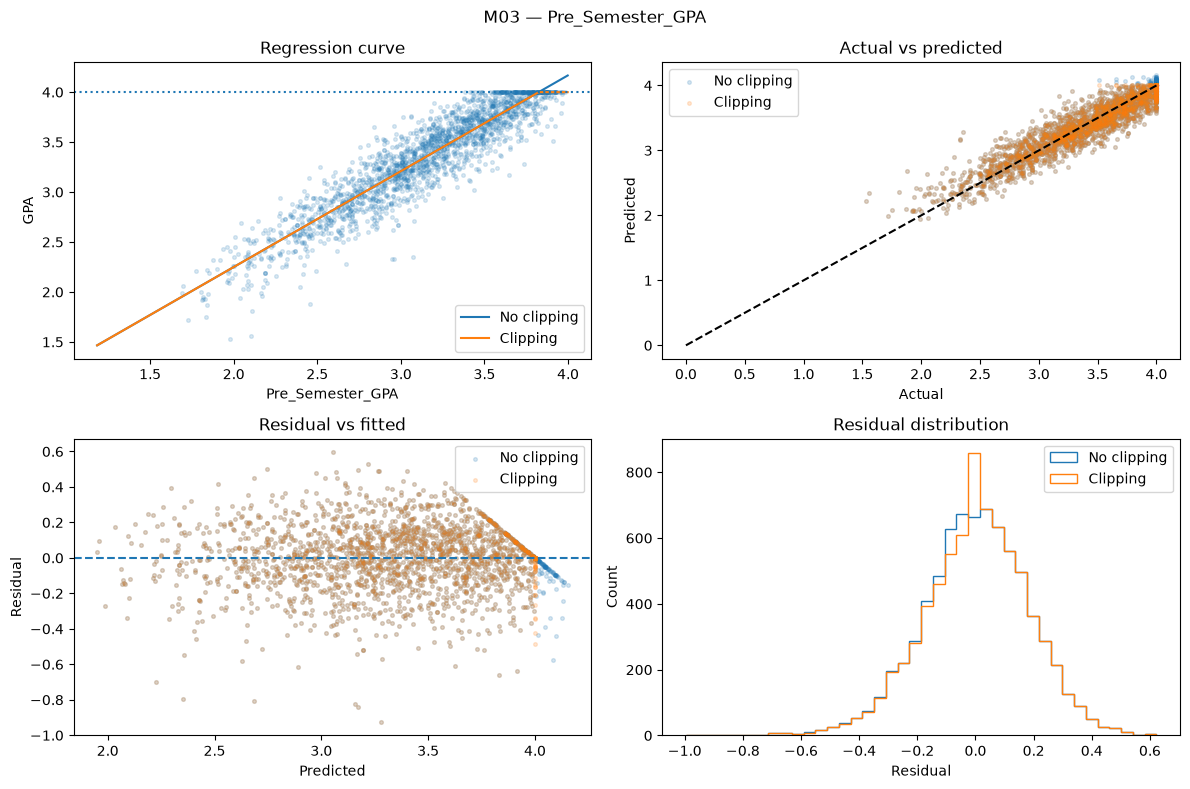

In [12]:
ts=test.sample(min(2000,len(test)),random_state=SEED)
for mid in ['M01','M03']:
    f=FEATURES[mid]; grid=pd.DataFrame({f:np.linspace(dev[f].min(),dev[f].max(),300)})
    fig,ax=plt.subplots(2,2,figsize=(12,8)); ax[0,0].scatter(ts[f],ts[TARGET],s=7,alpha=.16)
    for mode in MODES:
        model=final_models[(mid,mode)]; p=model.predict(ts[[f]]); r=ts[TARGET]-p
        ax[0,0].plot(grid[f],model.predict(grid),label=mode); ax[0,1].scatter(ts[TARGET],p,s=7,alpha=.18,label=mode)
        ax[1,0].scatter(p,r,s=7,alpha=.18,label=mode); ax[1,1].hist(test[TARGET]-model.predict(test[[f]]),bins=40,histtype='step',label=mode)
    ax[0,0].axhline(4,ls=':'); ax[0,0].set(xlabel=f,ylabel='GPA',title='Regression curve')
    ax[0,1].plot([0,4],[0,4],'k--'); ax[0,1].set(xlabel='Actual',ylabel='Predicted',title='Actual vs predicted')
    ax[1,0].axhline(0,ls='--'); ax[1,0].set(xlabel='Predicted',ylabel='Residual',title='Residual vs fitted')
    ax[1,1].set(xlabel='Residual',ylabel='Count',title='Residual distribution')
    for axis in ax.flat: axis.legend()
    fig.suptitle(mid+' — '+f); show(fig, f'06_final_test_diagnostics_{mid}')

### 10.1 | Phân tích tại biên GPA (Ceiling effect and changed predictions)

Để hiểu clipping tác động ở đâu, chia test thành hai nhóm theo nhãn thật: GPA = 4 và GPA < 4. Tính số mẫu, MAE, RMSE và mean residual riêng cho mỗi nhóm và mỗi model/mode. Nhóm GPA < 4 bao gồm cả GPA = 0; notebook không tách riêng nhóm sàn GPA.

Nếu A dự đoán vượt 4, clipping sẽ đưa về đúng 4; nếu actual = 4, sai số của mẫu đó bằng 0 sau clipping. Nếu actual dưới 4, sai số vẫn có thể tồn tại nhưng không lớn hơn lỗi raw. Clipping không sửa các prediction sai nhưng đã nằm trong miền hợp lệ.

Bảng subgroup giúp xem lợi ích có tập trung ở các sinh viên đạt trần hay không; đọc cùng `n` vì nhóm nhỏ có thể thiếu ổn định. Mean residual dương/âm chỉ ra xu hướng dự đoán thấp/cao trong nhóm. Các ví dụ `Raw` và `Clipped` là tối đa 5 mẫu đầu tiên thực sự thay đổi cho từng model, không phải mẫu chọn theo sai số lớn nhất hoặc đại diện ngẫu nhiên. Nếu không có ví dụ thì không có prediction bị thay đổi trên test đối với model đó.

Sự tích tụ tại trần có thể hạn chế một đường hồi quy thẳng, nhưng chưa đủ để kết luận nhãn là dữ liệu censored hay bị giới hạn bởi một cơ chế tạo dữ liệu cụ thể.

In [13]:
groups=[]; changed=[]
for mid,f in FEATURES.items():
    for mode in MODES:
        model=final_models[(mid,mode)]
        for label,mask in [('GPA = 4',test[TARGET].eq(4)),('GPA < 4',test[TARGET].lt(4))]:
            sub=test.loc[mask]
            if sub.empty: continue
            p=model.predict(sub[[f]])
            groups.append({'Model':mid,'Mode':mode,'Group':label,'n':len(sub),'MAE':mean_absolute_error(sub[TARGET],p),'RMSE':np.sqrt(mean_squared_error(sub[TARGET],p)),'Mean residual':(sub[TARGET]-p).mean()})
    z=final_models[(mid,'No clipping')].predict(test[[f]]); p=np.clip(z,*BOUNDS); mask=z!=p
    print(mid,'changed predictions:',int(mask.sum()))
    if mask.any():
        t=test.loc[mask,[ID,f,TARGET]].head(5).copy().rename(columns={f:'Feature value'}); t.insert(0,'Model',mid); t['Raw']=z[mask][:5]; t['Clipped']=p[mask][:5]; changed.append(t)
display(pd.DataFrame(groups).round(5))
if changed: display(pd.concat(changed,ignore_index=True).round(5))
pd.DataFrame(groups).to_csv(TABLES / 'final_test_subgroup_gpa.csv', index=False)
changed_examples = (pd.concat(changed, ignore_index=True) if changed else
                    pd.DataFrame(columns=['Model', ID, 'Feature value', TARGET, 'Raw', 'Clipped']))
changed_examples.to_csv(TABLES / 'clipped_prediction_examples.csv', index=False)


M01 changed predictions: 0
M02 changed predictions: 0
M03 changed predictions: 350
M04 changed predictions: 0
M05 changed predictions: 0


,Model,Mode,Group,n,MAE,RMSE,Mean residual
0,M01,No clipping,GPA = 4,722,0.65100,0.65109,0.65100
1,M01,No clipping,GPA < 4,6778,0.38040,0.47829,-0.07029
2,M01,Clipping,GPA = 4,722,0.65100,0.65109,0.65100
3,M01,Clipping,GPA < 4,6778,0.38040,0.47829,-0.07029
4,M02,No clipping,GPA = 4,722,0.62654,0.63028,0.62654
5,M02,No clipping,GPA < 4,6778,0.37811,0.47701,-0.06845
6,M02,Clipping,GPA = 4,722,0.62654,0.63028,0.62654
7,M02,Clipping,GPA < 4,6778,0.37811,0.47701,-0.06845
8,M03,No clipping,GPA = 4,722,0.11013,0.14475,0.06943
9,M03,No clipping,GPA < 4,6778,0.14802,0.18888,-0.00745


,Model,Student_ID,Feature value,Post_Semester_GPA,Raw,Clipped
0,M03,100124,3.856,4.000,4.03034,4.0
1,M03,100238,3.857,4.000,4.03130,4.0
2,M03,100249,3.915,4.000,4.08694,4.0
3,M03,100498,3.827,3.829,4.00252,4.0
4,M03,100526,3.948,4.000,4.11860,4.0


## 11 | Minh họa ứng dụng dự đoán (Prediction application)

Mục này triển khai một giao diện notebook đơn giản: người dùng chỉnh `MODEL_ID` và `INPUT_VALUE`, hàm `predict_gpa()` trả về bảng dự đoán A/B từ mô hình final refit. Đây là minh họa quy trình inference, không phải huấn luyện lại.

**Ví dụ:** `MODEL_ID='M03'`, `INPUT_VALUE=3.95` biểu thị GPA trước kỳ là 3.95; đổi sang M01 và giá trị phù hợp để thử số giờ GenAI mỗi tuần. Không nhập cả năm feature cùng lúc vì SLR chỉ nhận một biến. Hàm kiểm tra giá trị hữu hạn, không âm và các miền GPA/dependency trước dự đoán. Nếu feature nằm ngoài khoảng đã quan sát trên dev, hàm in cảnh báo ngoại suy.

Bảng output cho biết model, feature, giá trị đầu vào, mode và GPA prediction. Khi hai dự đoán khác nhau, mode B đảm bảo điểm thuộc [0,4]; tính hợp lệ về miền không đồng nghĩa với độ chính xác thực tế. Khi ngoại suy, ngay cả prediction đã clipping vẫn có thể thiếu tin cậy. Đây chỉ là demo học thuật, không phù hợp để ra quyết định học vụ về cá nhân.

In [14]:
def predict_gpa(model_id,value):
    f=FEATURES[model_id]; value=float(value)
    if not np.isfinite(value): raise ValueError('Input must be finite')
    if f=='Pre_Semester_GPA' and not 0<=value<=4: raise ValueError('GPA must be in [0,4]')
    if f=='Perceived_AI_Dependency' and not 1<=value<=10: raise ValueError('Dependency must be in [1,10]')
    if value<0: raise ValueError('Input must be nonnegative')
    if not dev[f].min()<=value<=dev[f].max(): print('Warning: outside observed feature range')
    X=pd.DataFrame({f:[value]})
    return pd.DataFrame([{'Model':model_id,'Feature':f,'Input':value,'Mode':mode,'Prediction':final_models[(model_id,mode)].predict(X)[0]} for mode in MODES])
MODEL_ID='M03'; INPUT_VALUE=3.95
display(predict_gpa(MODEL_ID,INPUT_VALUE).round(5))

,Model,Feature,Input,Mode,Prediction
0,M03,Pre_Semester_GPA,3.95,No clipping,4.12052
1,M03,Pre_Semester_GPA,3.95,Clipping,4.00000


## 12 | Báo cáo kết quả và thảo luận (Discussion & conclusion)

Phần dưới sinh báo cáo trực tiếp từ `final_results`, `delta`, `selected` và các estimator đã fit. Không chèn sẵn số liệu từ lần chạy khác. Sau khi chạy, đọc phần kết quả cùng các bảng đầy đủ ở mục 06–10; report tự động tập trung vào M01, M03 và ứng viên validation, nên không thay thế việc xem bảng của M02, M04, M05.

### 12.1 | Khung diễn giải kết quả
| Câu hỏi | Bằng chứng cần dùng |
|---|---|
| Feature GenAI có hữu ích không? | Slope M01, RMSE và R² trên test, Mean Baseline, scatter và residual |
| Feature nào dự đoán tốt hơn? | Xếp hạng validation đã khóa, CV mean/std, bảng test để mô tả hiệu năng cuối |
| Clipping giúp ở đâu? | Delta MAE/MSE/RMSE/R², số raw predictions ngoài biên, subgroup GPA = 4 |
| Mô hình còn hạn chế gì? | Residual patterns, sai số lớn, ngoại suy, nguồn dữ liệu và giao thức split |

Một chênh lệch metric nhỏ không tự chứng minh sự cải thiện có ý nghĩa thống kê. Nếu A/B giống nhau, cần ghi nhận kết quả đó thay vì cố tìm mức cải thiện. Nếu B tốt hơn, giải thích bằng phép chiếu lên miền hợp lệ, không quy công cho việc học tham số mới. Nếu một model khác M01 được chọn, vẫn phải trả lời câu hỏi M01 bằng kết quả riêng của nó.

### 12.2 | Giới hạn của nghiên cứu
SLR không kiểm soát biến gây nhiễu hoặc tương tác giữa các feature; liên hệ quan sát không phải quan hệ nhân quả. Khả năng đại diện, thời điểm ghi nhận feature và tính độc lập của split chưa được xác minh bằng nguồn độc lập. Không có external test qua trường hoặc học kỳ khác. Kiểm tra ID không phát hiện mọi dạng data leakage. Ngoài ra, clipping chỉ giải quyết miền đầu ra chứ không mô hình hóa cơ chế bão hòa. Các hạn chế này cần được cân nhắc trước khi sử dụng kết quả cho bất kỳ dự báo thực tế nào.

### 12.3 | Kết quả định lượng và kết luận tự động
Cell tiếp theo trình bày thiết lập, slope M01, các metrics M01/M03, kết quả lựa chọn validation, Mean Baseline, kết luận và hướng nghiên cứu tiếp theo dựa trên output hiện hành.

In [15]:
def row(mid,mode): return final_results[(final_results.Model==mid)&(final_results.Mode==mode)].iloc[0]
a=row('M01','No clipping'); b=row('M01','Clipping'); c=row('M03','No clipping'); d=row('M03','Clipping')
slope=final_models[('M01','No clipping')].model_.coef_[0]
lines=[f'**Dataset and setup.** {total_samples:,} retained samples from existing CSV partitions; train/validation/test = {len(train):,}/{len(val):,}/{len(test):,}; refit = {len(dev):,}. Train GPA at 4: {train[TARGET].eq(4).sum():,} ({100*train[TARGET].eq(4).mean():.2f}%).',
f'**M01 — GenAI hours.** Final slope {slope:+.6f} GPA per additional weekly hour (unadjusted association). Raw test MAE {a.MAE:.5f}, RMSE {a.RMSE:.5f}, R² {a.R2:.5f}; clipped MAE {b.MAE:.5f}, RMSE {b.RMSE:.5f}, R² {b.R2:.5f}. Raw out-of-range count: {int(a["Below 0"]+a["Above 4"])}.',
f'**M03 — prior GPA.** Raw RMSE {c.RMSE:.5f}, R² {c.R2:.5f}; clipped RMSE {d.RMSE:.5f}, R² {d.R2:.5f}. Raw above 4: {int(c["Above 4"])}. RMSE improvement: {delta.loc["M03","RMSE improvement (%)"]:.3f}%.',
f'**Validation selection.** No clipping: {selected["No clipping"]}; clipping: {selected["Clipping"]}. Mean baseline test RMSE {baseline_test["RMSE"]:.5f}.',
'**Conclusion.** Hệ số giống nhau; clipping đảm bảo đầu ra hợp lệ, chỉ thay đổi dự đoán ngoài miền. Metric tốt hơn (nếu có) do projection, không phải học hệ số tốt hơn. M01 phản ánh liên hệ đơn biến chứ không chứng minh tác động nhân quả của GenAI.',
'**Limitations and future work.** SLR không kiểm soát nhiễu/tương tác; nguồn và thời điểm ghi nhận feature chưa xác minh độc lập. Cách chia dữ liệu có sẵn chưa được xác minh độc lập và không chứng minh tổng quát hóa qua trường/kỳ học. Ceiling effect và ngoại suy cần được xem xét. Có thể nghiên cứu hồi quy đa biến hoặc bounded/censored regression trong thí nghiệm mới.']
display(Markdown('\n\n'.join(lines)))
(OUT / 'results_report.md').write_text('# SLR — Results and discussion\n\n' + '\n\n'.join(lines) + '\n', encoding='utf-8')


**Dataset and setup.** 50,000 retained samples from existing CSV partitions; train/validation/test = 35,000/7,500/7,500; refit = 42,500. Train GPA at 4: 3,369 (9.63%).

**M01 — GenAI hours.** Final slope -0.001351 GPA per additional weekly hour (unadjusted association). Raw test MAE 0.40645, RMSE 0.49754, R² -0.00069; clipped MAE 0.40645, RMSE 0.49754, R² -0.00069. Raw out-of-range count: 0.

**M03 — prior GPA.** Raw RMSE 0.18509, R² 0.86152; clipped RMSE 0.18395, R² 0.86322. Raw above 4: 350. RMSE improvement: 0.616%.

**Validation selection.** No clipping: M03; clipping: M03. Mean baseline test RMSE 0.49737.

**Conclusion.** Hệ số giống nhau; clipping đảm bảo đầu ra hợp lệ, chỉ thay đổi dự đoán ngoài miền. Metric tốt hơn (nếu có) do projection, không phải học hệ số tốt hơn. M01 phản ánh liên hệ đơn biến chứ không chứng minh tác động nhân quả của GenAI.

**Limitations and future work.** SLR không kiểm soát nhiễu/tương tác; nguồn và thời điểm ghi nhận feature chưa xác minh độc lập. Cách chia dữ liệu có sẵn chưa được xác minh độc lập và không chứng minh tổng quát hóa qua trường/kỳ học. Ceiling effect và ngoại suy cần được xem xét. Có thể nghiên cứu hồi quy đa biến hoặc bounded/censored regression trong thí nghiệm mới.

1269

## 13 | Tài liệu tham khảo và khả năng tái lập (References)

1. Dataset sử dụng thực tế: `train/dataset.csv`, `validation/dataset.csv`, `test/dataset.csv` trong `LAB01_DATA_ROOT`. Nguồn Kaggle ghi trong notebook SLR tham chiếu: [Impact of AI on Students](https://www.kaggle.com/datasets/laveshjadon/ai-impact-on-students/data). Nguồn gốc và cơ chế tạo dữ liệu chưa được xác minh độc lập; dùng SHA-256 và ID trong notebook để xác nhận phiên bản dữ liệu.
2. *Lab 01: Linear Regression Project*, mục 3–4 — yêu cầu định nghĩa bài toán, xây dựng mô hình, đánh giá và diễn giải kết quả, minh họa ứng dụng.
3. `Lab01_Simple_Linear_Regression.ipynb` — cấu hình SLR tham chiếu. Notebook IRL nguyên bản chưa được truy xuất trực tiếp; quy ước clipping và refit dựa trên mô tả đã có. Cần đối chiếu với IRL về split, cleaning, metric, chính sách clipping và final refit trước khi so sánh giữa hai họ mô hình.
4. Tài liệu API scikit-learn: [LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html), [KFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html), [Regression metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics). Tham khảo để giải thích các API sử dụng trong code.
5. Tài liệu NumPy: [numpy.clip](https://numpy.org/doc/stable/reference/generated/numpy.clip.html).

### Checklist chạy lại
- Cấu hình `.env` và kiểm tra đường dẫn của ba CSV.
- Restart Kernel & Run All; lưu phiên bản thư viện, SHA-256, audit và split table.
- Kiểm tra các assertion về ID, hệ số A/B và delta metrics.
- Đọc validation selection trước bảng test; lưu bảng, biểu đồ và báo cáo tự động sau khi chạy.
- Đối chiếu dữ liệu và giao thức với IRL trước khi sử dụng bảng so sánh chung.

Notebook được hỗ trợ xây dựng bằng ChatGPT như tài liệu tham khảo. Sinh viên cần tự kiểm tra, hiểu công thức, chỉnh sửa nhận xét dựa trên kết quả và ghi nhận tài liệu hỗ trợ theo quy định Lab 01. Notebook không thay thế báo cáo PDF hoặc video demo nếu môn học yêu cầu.

## 14 | Xuất kết quả và kiểm tra artifact (Export & reproducibility)

Các file đầu ra được tổ chức theo cấu trúc IRL: mỗi run có provenance, model lock, metrics, registry và manifest; các bảng/biểu đồ/mô hình nằm trong thư mục riêng. Không thay đổi quy tắc chọn SLR theo validation, không chọn lại dựa trên test. Các model M01–M05 đều được đánh giá theo hai chính sách trên cùng tập test.

Để tránh phụ thuộc lớp `GPARegressor` định nghĩa trong notebook khi load ở script khác, mỗi Joblib lưu một dictionary gồm estimator `LinearRegression` chuẩn của scikit-learn, tên feature và chính sách clipping. Dùng `bundle['estimator'].predict(X)` rồi `np.clip` nếu `bundle['clipping']` là `True`. Chỉ load Joblib từ nguồn đáng tin cậy. `selected_train_plus_validation.joblib` chứa hai bundle được chọn theo validation (một cho mỗi policy).

`final_test_predictions.csv` có một dòng cho mỗi cặp sinh viên–model (5 dòng mỗi sinh viên), gồm raw và clipped prediction cùng residual. Các metric JSON dùng tên thường như IRL. Registry đánh dấu việc tái sử dụng test và giữ nguyên hồ sơ lần đầu; SLR vẫn chạy test mỗi lần Run All như trước, không áp dụng khóa bắt buộc/smoke mode của IRL. Nếu đánh giá lại, chỉ dùng để kiểm tra tái lập, không tuning. Student ID có trong các bảng dự đoán và fold assignment; không công khai nếu chứa thông tin cá nhân.


In [16]:
# Export paired predictions, metrics, reusable models and run manifest.
def bundle_for(mid, mode):
    model = final_models[(mid, mode)]
    return {'model_id': mid, 'feature': FEATURES[mid], 'estimator': model.model_,
            'clipping': bool(MODES[mode]), 'bounds': BOUNDS,
            'prediction_policy': 'clip_0_4' if MODES[mode] else 'raw_ols',
            'run_id': RUN_ID}

def predict_bundle(bundle, X):
    raw = bundle['estimator'].predict(X[[bundle['feature']]])
    return np.clip(raw, *bundle['bounds']) if bundle['clipping'] else raw

selected_bundles = {mode: bundle_for(mid, mode) for mode, mid in selected.items()}
joblib.dump(selected_bundles, MODELS / 'selected_train_plus_validation.joblib')
model_files = []
prediction_frames = []
y_test = test[TARGET].to_numpy(float)
for mid, feature in FEATURES.items():
    X = test[[feature]]
    raw = final_models[(mid, 'No clipping')].predict(X)
    clipped = final_models[(mid, 'Clipping')].predict(X)
    np.testing.assert_allclose(clipped, np.clip(raw, *BOUNDS))
    prediction_frames.append(pd.DataFrame({
        ID: test[ID].to_numpy(), 'model': mid, 'feature': feature,
        'feature_value': X[feature].to_numpy(), 'actual': y_test,
        'predicted': clipped, 'predicted_raw': raw, 'was_clipped': raw != clipped,
        'residual': y_test - clipped, 'residual_raw': y_test - raw,
        'absolute_error': np.abs(y_test - clipped), 'absolute_error_raw': np.abs(y_test - raw)}))
    for mode, clipping in MODES.items():
        dest = MODELS / f'{mid}_{"clip_0_4" if clipping else "raw_ols"}.joblib'
        joblib.dump(bundle_for(mid, mode), dest)
        restored = joblib.load(dest)
        np.testing.assert_allclose(predict_bundle(restored, X), final_models[(mid, mode)].predict(X))
        model_files.append(dest)

predictions = pd.concat(prediction_frames, ignore_index=True)
pred_path = TABLES / 'final_test_predictions.csv'
predictions.to_csv(pred_path, index=False)
comparison = final_results.rename(columns={'Model':'model','Feature':'feature','Mode':'mode',
                                         'MAE':'mae','MSE':'mse','RMSE':'rmse','R2':'r2'}).copy()
comparison['n'] = len(test)
base = {'model':'Mean baseline (train+validation)', 'mode':'baseline', 'n':len(test),
        **{k.lower():float(baseline_test[k]) for k in ['MAE','MSE','RMSE','R2']}}
comparison = pd.concat([comparison, pd.DataFrame([base])], ignore_index=True)
comparison.to_csv(TABLES / 'final_test_comparison.csv', index=False)
delta.to_csv(TABLES / 'clipping_comparison.csv', index_label='model')

# Match IRL metric names and verify them against the exported predictions.
def core_metrics(y, p):
    return {k.lower(): float(v) for k,v in metrics(np.asarray(y),np.asarray(p)).items()
            if k in ['MAE','MSE','RMSE','R2']}

saved = pd.read_csv(pred_path, dtype={ID: str})
assert len(saved) == len(test) * len(FEATURES)
assert not saved.duplicated([ID,'model']).any()
assert saved['predicted'].between(*BOUNDS).all()
np.testing.assert_allclose(saved['predicted'], np.clip(saved['predicted_raw'], *BOUNDS), atol=1e-10)
np.testing.assert_allclose(saved['residual'], saved['actual'] - saved['predicted'], atol=1e-10)
np.testing.assert_allclose(saved['residual_raw'], saved['actual'] - saved['predicted_raw'], atol=1e-10)
per_model = {}
for mid in FEATURES:
    sub = saved.loc[saved['model'].eq(mid)]
    assert sub[ID].tolist() == test[ID].astype(str).tolist()
    np.testing.assert_allclose(sub['actual'], y_test)
    raw_met = core_metrics(sub['actual'], sub['predicted_raw'])
    clip_met = core_metrics(sub['actual'], sub['predicted'])
    for mode, values in [('No clipping', raw_met), ('Clipping', clip_met)]:
        expected = final_results.loc[final_results.Model.eq(mid) & final_results.Mode.eq(mode)].iloc[0]
        for key, value in values.items():
            np.testing.assert_allclose(value, expected[{'mae':'MAE','mse':'MSE','rmse':'RMSE','r2':'R2'}[key]], atol=1e-10)
    per_model[mid] = {'n': len(sub), 'raw_metrics': raw_met, 'clipped_metrics': clip_met,
                      'clipped_pct': float(100 * sub['was_clipped'].mean())}

all_metrics = {'run_id': RUN_ID, 'selected_model': selected,
               'prediction_policies': ['raw_ols','clip_0_4'],
               'development_comparison': development.to_dict('records'),
               'final_test': {'status':'executed', 'n':len(test), 'test_reused':bool(previous_runs),
                              'previous_test_run_ids':previous_runs, 'per_model':per_model,
                              'baseline_metrics': {k.lower():float(baseline_test[k]) for k in ['MAE','MSE','RMSE','R2']}}}
write_json(OUT / 'metrics.json', all_metrics)
record = {'run_id': RUN_ID, 'selected': selected, 'frozen_test_sha256': provenance['sha256']['test'],
          'comparison_protocol': 'paired_raw_vs_clip_0_4_v1', 'prediction_policies':['raw_ols','clip_0_4'],
          'test_reused':bool(previous_runs), 'previous_test_run_ids':previous_runs,
          'metrics_path':str(OUT / 'metrics.json'), 'recorded_utc':datetime.now(timezone.utc).isoformat()}
write_json(OUT / 'final_test_registry.json', record)
try:
    with prior_path.open('x', encoding='utf-8') as stream:
        json.dump(record, stream, indent=2, ensure_ascii=False, allow_nan=False)
except FileExistsError:
    pass  # First recorded run remains immutable.

required = [OUT / name for name in ['split_provenance.json','model_lock.json','metrics.json',
                                    'final_test_registry.json','results_report.md']]
required += [TABLES / name for name in ['development_comparison.csv','cv_folds.csv','train_cv_fold_assignments.csv',
                  'final_test_predictions.csv','final_test_comparison.csv','final_test_subgroup_gpa.csv']]
required += model_files + [MODELS / 'selected_train_plus_validation.joblib']
required += [OUT / f for f in FIGURES_CREATED]
assert len(FIGURES_CREATED) == len(set(FIGURES_CREATED)) == 8
assert all(p.is_file() and p.stat().st_size > 0 for p in required)
manifest = {'run_id':RUN_ID, 'started_with_frozen_csv':True, 'test_status':'executed',
            'csv_sha256':provenance['sha256'], 'selected':selected,
            'created_figures':FIGURES_CREATED, 'figure_count':len(FIGURES_CREATED),
            'functional_tests':{'model_reload':'passed','predictions':'passed','artifacts':'passed'},
            'environment':{'python':sys.version.split()[0],'sklearn':sklearn.__version__,
                           'numpy':np.__version__,'pandas':pd.__version__,'joblib':joblib.__version__},
            'required_artifacts':[str(p.relative_to(OUT)) for p in required],
            'artifacts':[str(p.relative_to(OUT)) for p in sorted(OUT.rglob('*')) if p.is_file()] + ['run_manifest.json'],
            'created_utc':datetime.now(timezone.utc).isoformat()}
write_json(OUT / 'run_manifest.json', manifest)
print('PASS: artifact verification | figures:', len(FIGURES_CREATED))
print('Output:', OUT)
print('Metrics:', OUT / 'metrics.json')
print('Tables:', TABLES)
print('Models:', MODELS)
print('Manifest:', OUT / 'run_manifest.json')


PASS: artifact verification | figures: 8
Output: D:\1_Study\3.Year 3\Semester_1\Intro_ML\Lab01\outputs\simple\runs\20261125_105509_d606e49
Metrics: D:\1_Study\3.Year 3\Semester_1\Intro_ML\Lab01\outputs\simple\runs\20261125_105509_d606e49\metrics.json
Tables: D:\1_Study\3.Year 3\Semester_1\Intro_ML\Lab01\outputs\simple\runs\20261125_105509_d606e49\tables
Models: D:\1_Study\3.Year 3\Semester_1\Intro_ML\Lab01\outputs\simple\runs\20261125_105509_d606e49\models
Manifest: D:\1_Study\3.Year 3\Semester_1\Intro_ML\Lab01\outputs\simple\runs\20261125_105509_d606e49\run_manifest.json
